# AULA 7 — KNN: K-Vizinhos Mais Próximos

### Mineração de Dados | Curso de Análise e Desenvolvimento de Sistemas (ADS)
Profa. Ana Paula

**Como podemos classificar algo novo observando exemplos parecidos que já conhecemos?**

> **Notebook resolvido.** O material da aula foi mantido como estava; as células
> de solução das **Atividades 1 a 11** foram preenchidas com código e cada uma
> ganhou uma célula de **interpretação** logo abaixo. As figuras ao fim de
> algumas soluções são salvas em `figuras/` e usadas no relatório em PDF da
> atividade avaliativa.

## 1. O que é KNN?

O **K-Nearest Neighbors (KNN)**, ou **K-Vizinhos Mais Próximos**, é um algoritmo de **aprendizado supervisionado** que utiliza exemplos já conhecidos para realizar previsões sobre novos registros.

Pense na seguinte situação: você conhece vários jogos e seus gêneros. Surge um jogo novo. Você compara suas características com as de jogos já classificados. Se os jogos mais parecidos forem do gênero *Aventura*, o novo jogo provavelmente receberá essa categoria.

**Ideia central:** *um novo registro tende a receber uma resposta semelhante às respostas de seus vizinhos mais próximos.*

- **Classificação:** resposta é uma **categoria** (por exemplo, Aventura ou Estratégia).
- **Regressão:** resposta é um **número** (por exemplo, duração estimada de uma partida).

Ao contrário de uma Árvore de Decisão, que aprende regras de separação, o KNN é um método **baseado em exemplos**: durante o `fit`, ele armazena a base de treinamento (e pode estruturar a busca); na previsão, consulta os exemplos mais próximos.

**Atenção:** o **KNN (supervisionado)** não deve ser confundido com o **K-Means (agrupamento não supervisionado)**.

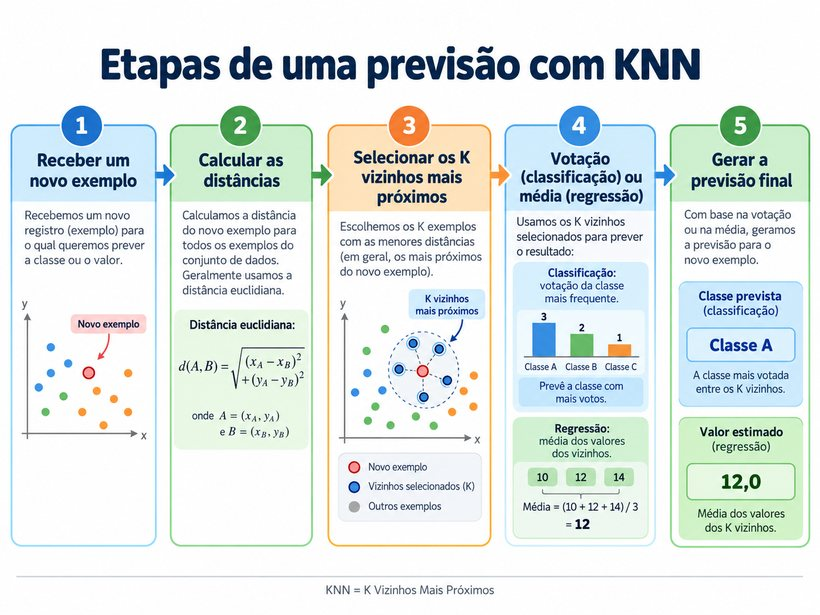

*Figura 1. Etapas de uma previsão com KNN*

### 1.1 Experimento: a classificação de um novo jogo

Uma plataforma tem seis jogos previamente classificados em duas categorias: **Estratégia (E)** e **Ação (A)**. Para tornar o problema simples, usamos duas características numéricas fictícias: **complexidade** e **ritmo** (escala de 0 a 6).

| Jogo | Complexidade | Ritmo | Categoria |
|---|---:|---:|---|
| J1 | 1 | 1 | Estratégia |
| J2 | 2 | 1 | Estratégia |
| J3 | 2 | 3 | Estratégia |
| J4 | 4 | 3 | Ação |
| J5 | 5 | 4 | Ação |
| J6 | 6 | 4 | Ação |

**Jogo novo:** complexidade = **3,4**; ritmo = **2,1**.

Qual categoria você escolheria? Seria melhor consultar apenas um jogo parecido ou três jogos parecidos?

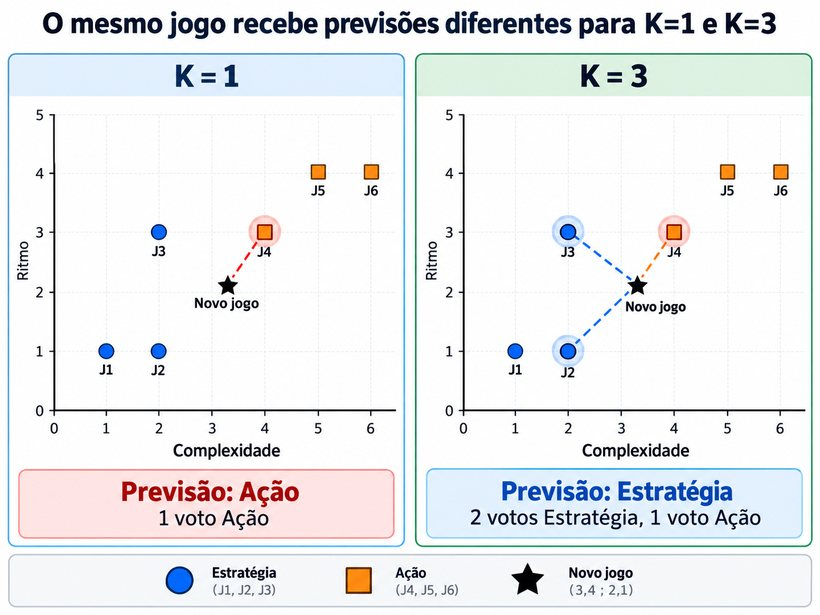

*Figura 2. O mesmo jogo recebe previsões diferentes para K=1 e K=3*

### 1.2 O que significa K?

**K indica quantos vizinhos participarão da decisão.**

- **K = 1:** somente o registro mais próximo decide.
- **K = 3:** os três vizinhos mais próximos votam.
- **K = 5:** cinco vizinhos participam da decisão.

Em classificação, normalmente vence a **categoria com maior número de votos**. Em regressão, a previsão padrão é a **média** dos valores dos vizinhos. Também é possível dar maior peso aos registros mais próximos.

Por que o mesmo jogo poderia ser classificado de modo diferente quando K muda?

## 2. Como o algoritmo mede a semelhança?

O KNN precisa de uma forma de medir a **proximidade** entre registros. Para características numéricas, duas opções comuns são:

**Distância euclidiana (reta entre dois pontos):**

$$d_E(x, z) = \sqrt{\sum_{j=1}^{p} (x_j - z_j)^2}$$

Para duas características:

$$d_E(A, B) = \sqrt{(x_A - x_B)^2 + (y_A - y_B)^2}$$

**Distância Manhattan (soma dos deslocamentos por eixo):**

$$d_M(x, z) = \sum_{j=1}^{p} |x_j - z_j|$$

A letra *p*, nas fórmulas acima, indica o número de atributos; mais adiante, no Scikit-learn, `p` será o parâmetro da distância de Minkowski: `p=1` equivale à Manhattan e `p=2` à euclidiana.

### 2.1 Resolução manual

Vamos calcular a distância do jogo novo **(3,4; 2,1)** até o jogo **J4 = (4; 3)**:

$$d_E = \sqrt{(3{,}4 - 4)^2 + (2{,}1 - 3)^2} = \sqrt{0{,}36 + 0{,}81} = \sqrt{1{,}17} \approx 1{,}082$$

Agora repita para os demais jogos e ordene as distâncias.

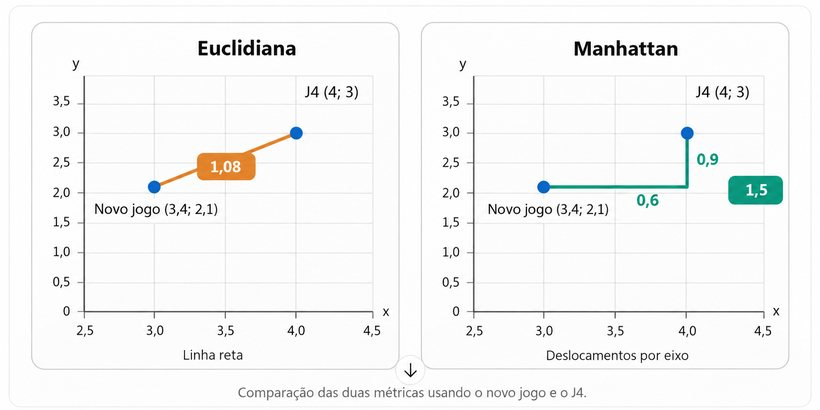

*Comparação das duas métricas usando o novo jogo e o J4.*

## Algoritmo K-nn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

jogos = pd.DataFrame({
    'jogo': ['J1','J2','J3','J4','J5','J6'],
    'complexidade': [1,2,2,4,5,6],
    'ritmo': [1,1,3,3,4,4],
    'categoria': ['Estratégia','Estratégia','Estratégia','Ação','Ação','Ação']
})

novo_jogo = np.array([3.4, 2.1])
print('Base de treinamento:')
display(jogos)

Base de treinamento:


,jogo,complexidade,ritmo,categoria
0,J1,1,1,Estratégia
1,J2,2,1,Estratégia
2,J3,2,3,Estratégia
3,J4,4,3,Ação
4,J5,5,4,Ação
5,J6,6,4,Ação


In [2]:
# Calculando a distância euclidiana manualmente, com NumPy
jogos['distancia_euclidiana'] = np.sqrt(
    (jogos['complexidade'] - novo_jogo[0])**2 +
    (jogos['ritmo'] - novo_jogo[1])**2
)

ranking = jogos.sort_values('distancia_euclidiana')
print('Vizinhos em ordem de proximidade:')
display(ranking[['jogo','categoria','distancia_euclidiana']].round(3))

Vizinhos em ordem de proximidade:


,jogo,categoria,distancia_euclidiana
3,J4,Ação,1.082
2,J3,Estratégia,1.664
1,J2,Estratégia,1.780
4,J5,Ação,2.484
0,J1,Estratégia,2.640
5,J6,Ação,3.220


In [3]:
# Configuração usada nas soluções das atividades (cores dos gráficos e pasta
# onde as figuras do relatório são salvas).
from pathlib import Path
from collections import Counter
import warnings

# Aviso inofensivo do NumPy ao transformar os resultados do GridSearchCV (cv_results_) em tabela
warnings.filterwarnings('ignore', message='invalid value encountered in cast', category=RuntimeWarning)

PASTA_FIGURAS = Path('figuras')
PASTA_FIGURAS.mkdir(exist_ok=True)
PASTA_RESULTADOS = Path('resultados')
PASTA_RESULTADOS.mkdir(exist_ok=True)

COR_ESTRATEGIA = '#2a78d6'   # azul
COR_ACAO = '#eb6834'         # laranja
COR_TREINO = '#2a78d6'
COR_TESTE = '#eb6834'
CORES_CATEGORIA = {'Estratégia': COR_ESTRATEGIA, 'Ação': COR_ACAO}

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'figure.dpi': 100})

def salvar(fig, nome):
    fig.savefig(PASTA_FIGURAS / f'{nome}.png', dpi=150, bbox_inches='tight')

### ✍️ Atividade 1 — Distâncias e votação

**Sem utilizar `KNeighborsClassifier`**, calcule as distâncias euclidianas para J2 e J3. Depois, com a tabela ordenada, determine a classificação do novo jogo para **K=1**, **K=3** e **K=5**.

**Registre também sua interpretação em uma célula de texto.**

In [4]:
# ATIVIDADE 1: solução

# 1) Distâncias de J2 e J3 passo a passo, sem KNeighborsClassifier
for nome in ['J2', 'J3']:
    linha = jogos.loc[jogos['jogo'] == nome].iloc[0]
    dx = novo_jogo[0] - linha['complexidade']
    dy = novo_jogo[1] - linha['ritmo']
    print(f"{nome} = ({linha['complexidade']}; {linha['ritmo']})")
    print(f"   d = raiz(({novo_jogo[0]} - {linha['complexidade']})² + ({novo_jogo[1]} - {linha['ritmo']})²)")
    print(f"     = raiz({dx**2:.2f} + {dy**2:.2f}) = raiz({dx**2 + dy**2:.2f}) = {np.sqrt(dx**2 + dy**2):.3f}\n")

# 2) Votação com a tabela ordenada, implementada à mão
def votar(ranking, k):
    vizinhos = ranking.head(k)
    votos = Counter(vizinhos['categoria'])
    vencedora = votos.most_common(1)[0][0]
    return vencedora, dict(votos), list(vizinhos['jogo'])

linhas = []
for k in [1, 3, 5]:
    categoria, votos, vizinhos = votar(ranking, k)
    linhas.append({'K': k, 'vizinhos': ', '.join(vizinhos),
                   'votos Estratégia': votos.get('Estratégia', 0),
                   'votos Ação': votos.get('Ação', 0),
                   'categoria prevista': categoria})
resultado_atividade1 = pd.DataFrame(linhas)
display(resultado_atividade1)

J2 = (2; 1)
   d = raiz((3.4 - 2)² + (2.1 - 1)²)
     = raiz(1.96 + 1.21) = raiz(3.17) = 1.780

J3 = (2; 3)
   d = raiz((3.4 - 2)² + (2.1 - 3)²)
     = raiz(1.96 + 0.81) = raiz(2.77) = 1.664



,K,vizinhos,votos Estratégia,votos Ação,categoria prevista
0,1,J4,0,1,Ação
1,3,"J4, J3, J2",2,1,Estratégia
2,5,"J4, J3, J2, J5, J1",3,2,Estratégia


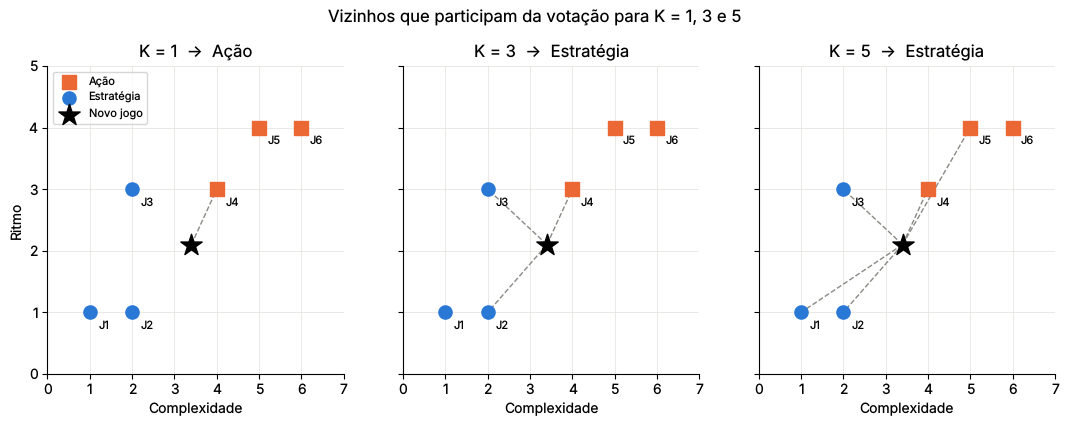

In [5]:
# Visualização: os vizinhos que votam em cada valor de K
fig, eixos = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for eixo, k in zip(eixos, [1, 3, 5]):
    vizinhos = ranking.head(k)
    for _, v in vizinhos.iterrows():
        eixo.plot([novo_jogo[0], v['complexidade']], [novo_jogo[1], v['ritmo']],
                  color='#8a8984', linewidth=1, linestyle='--', zorder=1)
    for categoria, grupo in jogos.groupby('categoria'):
        eixo.scatter(grupo['complexidade'], grupo['ritmo'], s=90,
                     color=CORES_CATEGORIA[categoria], label=categoria, zorder=3,
                     marker='o' if categoria == 'Estratégia' else 's')
    for _, j in jogos.iterrows():
        eixo.annotate(j['jogo'], (j['complexidade'], j['ritmo']),
                      textcoords='offset points', xytext=(6, -12), fontsize=8)
    eixo.scatter(*novo_jogo, marker='*', s=260, color='black', zorder=4, label='Novo jogo')
    categoria = votar(ranking, k)[0]
    eixo.set_title(f'K = {k}  →  {categoria}')
    eixo.set_xlabel('Complexidade')
    eixo.set_xlim(0, 7); eixo.set_ylim(0, 5)
eixos[0].set_ylabel('Ritmo')
eixos[0].legend(loc='upper left', fontsize=8)
fig.suptitle('Vizinhos que participam da votação para K = 1, 3 e 5', y=1.02)
salvar(fig, 'atividade1_vizinhos')
plt.show()

**Interpretação — Atividade 1**

As distâncias calculadas à mão são **J2 = 1,780** e **J3 = 1,664**, e coincidem com a tabela gerada pelo NumPy. Com a lista ordenada:

| K | Vizinhos | Votos | Previsão |
|---|---|---|---|
| 1 | J4 | 1 Ação | **Ação** |
| 3 | J4, J3, J2 | 2 Estratégia × 1 Ação | **Estratégia** |
| 5 | J4, J3, J2, J5, J1 | 3 Estratégia × 2 Ação | **Estratégia** |

O jogo novo está **na fronteira** entre os dois grupos. O único jogo de Ação próximo dele é o J4, que por acaso é o mais próximo de todos; por isso K=1 responde Ação. Quando mais vizinhos votam, J3 e J2 — os dois de Estratégia que vêm logo em seguida — viram a maioria. A mudança de resposta entre K=1 e K=3 não é um erro do algoritmo: é a própria definição de K mudando quem tem direito a voto. Isso responde à pergunta da seção 1.2.

Um detalhe: com K=5 entram J5 e J1, que estão bem mais longe (2,48 e 2,64), mas cada um tem **o mesmo peso no voto** que o J4 a 1,08. Isso motiva a opção `weights='distance'`, vista na seção 6.

## 3. Implementando o primeiro KNN em Python

Utilizaremos `KNeighborsClassifier` do Scikit-learn. Repare que o processo mantém a interface que você já conhece das Árvores de Decisão e do Random Forest:

1. Selecionar os atributos (`X`) e os rótulos (`y`).
2. Criar o classificador.
3. Executar `fit(X, y)`.
4. Executar `predict()` com um novo registro.

**Importante:** o exemplo é pequeno e serve para **entender a previsão**, não para medir a qualidade de generalização do algoritmo.

In [6]:
from sklearn.neighbors import KNeighborsClassifier

# X: informações de entrada; y: categoria que queremos prever
X = jogos[['complexidade', 'ritmo']]
y = jogos['categoria']

# Criar classificador e armazenar os exemplos
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X, y)

# Novo registro com nomes das colunas corretos
novo = pd.DataFrame([[3.4, 2.1]], columns=X.columns)

previsao = knn.predict(novo)
print('Categoria prevista:', previsao[0])  # Estratégia

Categoria prevista: Estratégia


In [7]:
# Descobrindo exatamente quais vizinhos foram usados

distancias, indices = knn.kneighbors(novo)
vizinhos = jogos.iloc[indices[0]][['jogo','categoria']].copy()
vizinhos['distancia'] = distancias[0]
print('Vizinhos que participaram da votação:')
display(vizinhos.round(3))

Vizinhos que participaram da votação:


,jogo,categoria,distancia
3,J4,Ação,1.082
2,J3,Estratégia,1.664
1,J2,Estratégia,1.780


### ✍️ Atividade 2 — Mude o número de vizinhos

Altere `n_neighbors` para **1, 3 e 5**. Mostre em uma tabela as três previsões e explique por que **K=1** pode ser muito sensível a um único exemplo atípico.

**Registre também sua interpretação em uma célula de texto.**

In [8]:
# ATIVIDADE 2: solução

linhas = []
for k in [1, 3, 5]:
    modelo = KNeighborsClassifier(n_neighbors=k).fit(X, y)
    _, indices = modelo.kneighbors(novo)
    linhas.append({'n_neighbors': k,
                   'vizinhos usados': ', '.join(jogos.iloc[indices[0]]['jogo']),
                   'categoria prevista': modelo.predict(novo)[0]})
display(pd.DataFrame(linhas))

# Demonstração da sensibilidade de K=1: um único exemplo atípico.
# O ponto (1,5; 1,5) está no meio dos jogos de Estratégia. Inserimos um único
# jogo "atípico" rotulado como Ação bem ao lado dele (por erro de cadastro,
# por exemplo) e vemos quem muda de opinião.
ponto = pd.DataFrame([[1.5, 1.5]], columns=X.columns)
atipico = pd.DataFrame({'jogo': ['J7 (atípico)'], 'complexidade': [1.6],
                        'ritmo': [1.4], 'categoria': ['Ação']})
jogos_com_atipico = pd.concat([jogos[['jogo','complexidade','ritmo','categoria']], atipico],
                              ignore_index=True)

linhas = []
for k in [1, 3, 5]:
    sem = KNeighborsClassifier(n_neighbors=k).fit(X, y).predict(ponto)[0]
    com = (KNeighborsClassifier(n_neighbors=k)
           .fit(jogos_com_atipico[['complexidade','ritmo']], jogos_com_atipico['categoria'])
           .predict(ponto)[0])
    linhas.append({'n_neighbors': k, 'sem o atípico': sem, 'com o atípico': com,
                   'mudou?': 'SIM' if sem != com else 'não'})
print('Ponto (1,5; 1,5) — efeito de um único exemplo atípico:')
display(pd.DataFrame(linhas))

,n_neighbors,vizinhos usados,categoria prevista
0,1,J4,Ação
1,3,"J4, J3, J2",Estratégia
2,5,"J4, J3, J2, J5, J1",Estratégia


Ponto (1,5; 1,5) — efeito de um único exemplo atípico:


,n_neighbors,sem o atípico,com o atípico,mudou?
0,1,Estratégia,Ação,SIM
1,3,Estratégia,Estratégia,não
2,5,Estratégia,Estratégia,não


**Interpretação — Atividade 2**

O `KNeighborsClassifier` reproduz exatamente a votação feita à mão na Atividade 1: **K=1 → Ação**, **K=3 → Estratégia**, **K=5 → Estratégia**.

K=1 é sensível porque **toda a decisão fica nas mãos de um único exemplo**. A segunda tabela mostra isso com um experimento: o ponto (1,5; 1,5) fica cercado de jogos de Estratégia, mas basta inserir **um** jogo rotulado como Ação ao lado dele (um erro de cadastro, por exemplo) para K=1 trocar a resposta. Com K=3 e K=5 o exemplo atípico é só um voto entre vários e é derrotado pela maioria.

Em termos gerais: K pequeno produz uma fronteira de decisão muito recortada, que acompanha cada ruído da base (**alta variância**); K maior suaviza a fronteira. O custo de aumentar K é que, se ele crescer demais, vizinhos distantes e pouco parecidos passam a votar — o que aparece na Atividade 8.

### ✍️ Atividade 3 — Prever vários registros

Classifique os três jogos fictícios **(1,5; 1,5)**, **(4,5; 3,5)** e **(3,4; 2,1)** para **K=1 e K=3**. Construa um `DataFrame` com os resultados.

**Registre também sua interpretação em uma célula de texto.**

In [9]:
# ATIVIDADE 3: solução

novos_jogos = pd.DataFrame([[1.5, 1.5], [4.5, 3.5], [3.4, 2.1]], columns=X.columns)

resultado_atividade3 = novos_jogos.copy()
for k in [1, 3]:
    modelo = KNeighborsClassifier(n_neighbors=k).fit(X, y)
    resultado_atividade3[f'K={k}'] = modelo.predict(novos_jogos)
    distancias, indices = modelo.kneighbors(novos_jogos)
    resultado_atividade3[f'vizinhos K={k}'] = [
        ', '.join(f"{jogos.iloc[i]['jogo']} ({d:.2f})" for i, d in zip(ind, dist))
        for ind, dist in zip(indices, distancias)]
resultado_atividade3['mudou com K?'] = np.where(
    resultado_atividade3['K=1'] != resultado_atividade3['K=3'], 'SIM', 'não')
display(resultado_atividade3)

,complexidade,ritmo,K=1,vizinhos K=1,K=3,vizinhos K=3,mudou com K?
0,1.5,1.5,Estratégia,J1 (0.71),Estratégia,"J1 (0.71), J2 (0.71), J3 (1.58)",não
1,4.5,3.5,Ação,J4 (0.71),Ação,"J4 (0.71), J5 (0.71), J6 (1.58)",não
2,3.4,2.1,Ação,J4 (1.08),Estratégia,"J4 (1.08), J3 (1.66), J2 (1.78)",SIM


**Interpretação — Atividade 3**

- **(1,5; 1,5)** está no meio dos jogos de Estratégia (J1 e J2, ambos a 0,71) → **Estratégia** com K=1 e K=3.
- **(4,5; 3,5)** está no meio dos jogos de Ação (J4 e J5, ambos a 0,71) → **Ação** com K=1 e K=3.
- **(3,4; 2,1)** é o jogo da fronteira → **Ação** com K=1 e **Estratégia** com K=3.

Só o registro de fronteira muda de resposta. Para pontos bem dentro de uma região, K quase não importa, porque todos os vizinhos próximos concordam. A escolha de K pesa justamente nos casos ambíguos — que costumam ser os mais difíceis e os mais importantes de acertar.

Repare também nos **empates de distância**: (1,5; 1,5) está à mesma distância de J1 e J2. Aqui não faz diferença porque os dois são de Estratégia, mas em outros casos o desempate depende da ordem das linhas na base (ver Atividade 4).

## 4. O KNN também pode fazer regressão

Na **classificação**, os vizinhos votam em uma categoria. Na **regressão**, o algoritmo devolve uma **estimativa numérica**, normalmente a média dos valores dos vizinhos.

Imagine que você deseja prever a **duração de uma partida de jogo** a partir da complexidade de jogos conhecidos. Uma média simples pode ser adequada como primeira aproximação.

In [10]:
from sklearn.neighbors import KNeighborsRegressor

duracao = pd.DataFrame({
    'complexidade': [1, 2, 3, 4, 5, 6],
    'minutos': [15, 20, 25, 40, 50, 55]
})

X_reg = duracao[['complexidade']]
y_reg = duracao['minutos']
regressor = KNeighborsRegressor(n_neighbors=3)
regressor.fit(X_reg, y_reg)

jogo_novo = pd.DataFrame({'complexidade':[3.5]})
print('Duração prevista:',regressor.predict(jogo_novo)[0],'minutos')

Duração prevista: 28.333333333333332 minutos


### ✍️ Atividade 4 — Classificação ou regressão?

Compare `KNeighborsRegressor(n_neighbors=1)` com `KNeighborsRegressor(n_neighbors=3)` para um jogo de **complexidade 3,5**. Qual o efeito de usar uma média de três vizinhos? E se o valor-alvo de um vizinho for um outlier?

**Registre também sua interpretação em uma célula de texto.**

In [11]:
# ATIVIDADE 4: solução

def prever_duracao(base, k):
    modelo = KNeighborsRegressor(n_neighbors=k).fit(base[['complexidade']], base['minutos'])
    distancias, indices = modelo.kneighbors(jogo_novo)
    vizinhos = base.iloc[indices[0]]
    return modelo.predict(jogo_novo)[0], vizinhos, distancias[0]

print('=== Base original ===')
for k in [1, 3]:
    valor, vizinhos, dist = prever_duracao(duracao, k)
    print(f'K={k}: {valor:.2f} min  ← vizinhos (complexidade, minutos, distância): '
          + '; '.join(f'({c}, {m}, {d:.1f})' for c, m, d in
                      zip(vizinhos['complexidade'], vizinhos['minutos'], dist)))

# ATENÇÃO: a complexidade 3,5 está exatamente no meio de 3 e 4 (distância 0,5
# para os dois). Há um EMPATE, e quem decide é a ordem das linhas na base.
invertida = duracao.iloc[::-1].reset_index(drop=True)
print(f'\nK=1 com a base em ordem inversa: {prever_duracao(invertida, 1)[0]:.2f} min '
      '(mesmos dados, só a ordem mudou)')

print('\n=== Efeito de um outlier (uma partida registrada com 200 minutos) ===')
linhas = []
for complexidade_outlier in [3, 4]:
    com_outlier = duracao.copy()
    com_outlier.loc[com_outlier['complexidade'] == complexidade_outlier, 'minutos'] = 200
    linhas.append({'outlier na complexidade': complexidade_outlier,
                   'K=1 (min)': round(prever_duracao(com_outlier, 1)[0], 2),
                   'K=3 (min)': round(prever_duracao(com_outlier, 3)[0], 2)})
display(pd.DataFrame(linhas))

=== Base original ===
K=1: 25.00 min  ← vizinhos (complexidade, minutos, distância): (3, 25, 0.5)
K=3: 28.33 min  ← vizinhos (complexidade, minutos, distância): (4, 40, 0.5); (3, 25, 0.5); (2, 20, 1.5)

K=1 com a base em ordem inversa: 40.00 min (mesmos dados, só a ordem mudou)

=== Efeito de um outlier (uma partida registrada com 200 minutos) ===


,outlier na complexidade,K=1 (min),K=3 (min)
0,3,200.0,86.67
1,4,25.0,81.67


**Interpretação — Atividade 4**

**Média de três vizinhos.** Com K=1 a previsão é **25 min** — o valor de um único jogo. Com K=3 é **28,33 min**, a média de 40, 25 e 20. A média suaviza a estimativa: ela deixa de copiar um exemplo e passa a combinar vários. Por isso, enquanto a classificação devolve uma categoria por **votação**, a regressão devolve um número por **média**.

**Um empate que muda o resultado.** A complexidade 3,5 está exatamente no meio de 3 e 4, a 0,5 de cada uma. Com K=1 há um empate, e o Scikit-learn decide pela **ordem das linhas**: com a base original a previsão é 25 min (complexidade 3); com a mesma base em ordem inversa, **40 min** (complexidade 4). Com K=3 o empate se repete entre as complexidades 2 e 5, ambas a 1,5. Em dados reais, com valores contínuos, empates exatos são raros, mas em escalas inteiras como esta eles aparecem — e vale saber que a resposta deixa de ser única.

**Outlier.** O efeito depende de **onde** o outlier cai:

- se ele está no vizinho que o K=1 escolhe (complexidade 3), K=1 devolve **200 min** inteiros, enquanto K=3 dilui para **86,67 min**;
- se está na complexidade 4, o K=1 nem o enxerga (25 min, porque o empate foi decidido para o lado da complexidade 3), mas o K=3 o inclui e sobe para **81,67 min**.

Ou seja, a média de três vizinhos **não elimina** um outlier: ela o **dilui**, dividindo seu peso por três — em compensação, aumenta a chance de ele participar da conta. Em média, ao longo de muitas previsões, diluir é melhor do que apostar tudo em um único vizinho, mas a média aritmética continua sensível a valores extremos. Uma alternativa mais robusta seria usar a **mediana** dos vizinhos.

## 5. A importância da normalização no KNN

O KNN **depende diretamente das distâncias**. Se utilizarmos duas variáveis com escalas muito diferentes, a variável com números maiores pode dominar o cálculo.

**Exemplo:** comparar clientes fictícios usando **idade (anos)** e **renda mensal (R$)**. A renda costuma variar em milhares, enquanto a idade varia em dezenas. Isso não significa que a renda deva ser milhares de vezes mais importante!

Há duas transformações bastante utilizadas:

**Min-Max (normalização):**

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

**Z-score (padronização):**

$$z = \frac{x - \mu}{\sigma}$$

Para esta aula, utilizaremos principalmente `StandardScaler` (padronização). Ele estima as médias e os desvios-padrão dos atributos **somente com os dados de treino**.

> **Regra:** primeiro separar treino e teste. Depois padronizar usando apenas as estatísticas de treino. Com `Pipeline`, o Scikit-learn controla automaticamente essa sequência.

In [12]:
from sklearn.preprocessing import StandardScaler

# Exemplo mínimo apenas para visualizar o efeito das escalas
base_escala = pd.DataFrame({
    'idade':[20,50], 'renda':[2000,2050], 'classe':['Grupo A','Grupo B']
})
X_escala = base_escala[['idade','renda']]
y_escala = base_escala['classe']
novo_escala = pd.DataFrame([[48,2005]],columns=X_escala.columns)

bruto = KNeighborsClassifier(n_neighbors=1).fit(X_escala,y_escala)
print('Sem padronização:',bruto.predict(novo_escala)[0])

padronizador = StandardScaler()
X_escala_pad = padronizador.fit_transform(X_escala)
novo_escala_pad = padronizador.transform(novo_escala)
normalizado = KNeighborsClassifier(n_neighbors=1).fit(X_escala_pad,y_escala)
print('Com padronização:',normalizado.predict(novo_escala_pad)[0])
print('Dados padronizados:')
print(X_escala_pad)

Sem padronização: Grupo A
Com padronização: Grupo B
Dados padronizados:
[[-1. -1.]
 [ 1.  1.]]


### 5.1 Por que usar `Pipeline`?

`Pipeline` reúne o pré-processamento e o classificador, evitando esquecer a transformação durante a previsão. Também ajuda a prevenir **vazamento de dados** ao fazer validação cruzada.

A sequência correta é:

**Treino/teste → `Pipeline(StandardScaler, KNN)` → treino → previsão → avaliação.**

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

# Dataset sintético apenas para demonstrar um protocolo completo
from sklearn.datasets import make_classification
X_sint, y_sint = make_classification(
    n_samples=350, n_features=2, n_informative=2,
    n_redundant=0, n_clusters_per_class=1,
    class_sep=1.15, random_state=42
)
X_sint[:,1] = X_sint[:,1] * 1000  # simula escalas diferentes

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X_sint, y_sint, test_size=0.25, random_state=42, stratify=y_sint
)

knn_sem_escala = KNeighborsClassifier(n_neighbors=5)
knn_com_escala = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5))

for nome,modelo in [('Sem padronizar',knn_sem_escala),('Com padronização',knn_com_escala)]:
    modelo.fit(X_treino,y_treino)
    print(nome,'| acurácia de teste:',round(modelo.score(X_teste,y_teste),3))

Sem padronizar | acurácia de teste: 0.659
Com padronização | acurácia de teste: 0.989


### ✍️ Atividade 5 — Influência da escala

Refaça o experimento anterior **sem multiplicar por 1000** a segunda coluna. Compare os resultados e explique se a padronização deve ser feita antes ou depois de separar treinamento e teste.

**Registre também sua interpretação em uma célula de texto.**

In [14]:
# ATIVIDADE 5: solução

X_orig, y_orig = make_classification(
    n_samples=350, n_features=2, n_informative=2,
    n_redundant=0, n_clusters_per_class=1,
    class_sep=1.15, random_state=42
)   # sem a multiplicação por 1000
print('Desvio-padrão de cada coluna (sem ×1000):', X_orig.std(axis=0).round(3))
print('Desvio-padrão de cada coluna (com ×1000):', X_sint.std(axis=0).round(3))

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(
    X_orig, y_orig, test_size=0.25, random_state=42, stratify=y_orig)

linhas = []
for cenario, (Xtr_, Xte_, ytr_, yte_) in [
        ('2ª coluna × 1000', (X_treino, X_teste, y_treino, y_teste)),
        ('escala original', (Xa_tr, Xa_te, ya_tr, ya_te))]:
    sem = KNeighborsClassifier(n_neighbors=5).fit(Xtr_, ytr_).score(Xte_, yte_)
    com = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xtr_, ytr_).score(Xte_, yte_)
    linhas.append({'cenário': cenario, 'sem padronizar': round(sem, 3),
                   'com padronização': round(com, 3)})
display(pd.DataFrame(linhas))

# Antes ou depois da separação? Comparação das estatísticas que o scaler aprende.
scaler_errado = StandardScaler().fit(X_sint)        # visto ANTES da separação: usa o teste
scaler_certo = StandardScaler().fit(X_treino)       # visto DEPOIS: só o treino
print('\nMédias aprendidas pelo scaler')
print('   ajustado em todos os dados (errado):', scaler_errado.mean_.round(3))
print('   ajustado só no treino (certo)     :', scaler_certo.mean_.round(3))

Desvio-padrão de cada coluna (sem ×1000): [1.206 0.393]


Desvio-padrão de cada coluna (com ×1000): [  1.206 392.746]


,cenário,sem padronizar,com padronização
0,2ª coluna × 1000,0.659,0.989
1,escala original,0.989,0.989



Médias aprendidas pelo scaler
   ajustado em todos os dados (errado): [3.000000e-03 1.149226e+03]
   ajustado só no treino (certo)     : [   0.    1167.392]


**Interpretação — Atividade 5**

Sem a multiplicação por 1000, as duas colunas já estão em escalas parecidas (desvios de 1,21 e 0,39) e o KNN acerta **0,989 com e sem padronização** — o mesmo valor. Com a segunda coluna multiplicada por 1000, o KNN sem padronizar cai para **0,659**: a distância passa a ser praticamente só a diferença na segunda coluna, e a primeira, que também separa as classes, é ignorada. A padronização recoloca as duas colunas no mesmo peso e volta a **0,989**.

Conclusão: a padronização não "melhora" o KNN por si só; ela **impede que uma coluna domine a distância apenas por estar numa unidade maior**. Quando as escalas já são comparáveis, ela é quase neutra; quando não são, é decisiva. Como no mundo real raramente se sabe de antemão, padronizar no KNN é a prática segura.

**Antes ou depois de separar?** **Depois.** O `StandardScaler` aprende média e desvio-padrão; se for ajustado antes da separação, ele usa informação do conjunto de teste — o que aparece nas médias diferentes impressas acima. Isso é **vazamento de dados**: o teste deixa de ser um conjunto realmente novo, e a avaliação tende a sair otimista. Aqui a diferença é pequena — na segunda coluna, 1149 contra 1167, menos de 5% de um desvio-padrão —, mas o princípio vale sempre. O `Pipeline` resolve isso automaticamente: o `fit` só enxerga o treino, e no teste o scaler apenas aplica (`transform`) o que aprendeu.

## 6. Principais hiperparâmetros do KNN

No Scikit-learn, utilizamos `sklearn.neighbors.KNeighborsClassifier` ou `KNeighborsRegressor`.

| Parâmetro | O que controla | Exemplos |
|---|---|---|
| `n_neighbors` | Quantos vizinhos serão utilizados | `1`, `3`, `5`, `7` |
| `weights` | Peso de cada vizinho no resultado | `'uniform'`, `'distance'` |
| `metric` | Medida utilizada para calcular a distância | `'minkowski'`, `'euclidean'`, `'manhattan'` |
| `p` | Expoente da distância de Minkowski, quando aplicável | `1` (Manhattan), `2` (Euclidiana) |
| `algorithm` | Estratégia de busca dos vizinhos | `'auto'`, `'brute'`, `'kd_tree'`, `'ball_tree'` |
| `leaf_size` | Parâmetro de busca em árvores KD/Ball | `30` |
| `n_jobs` | Paralelismo nas buscas suportadas | `None`, `-1` |

### 6.1 Como interpretar `weights`?

- `weights='uniform'`: todos os K vizinhos têm a mesma influência no voto.
- `weights='distance'`: vizinhos mais próximos recebem maior peso (aproximadamente inverso da distância); isso pode mudar o resultado.

**Pergunta importante:** K grande é sempre melhor? **Não.** K muito pequeno tende a ser instável, e K excessivamente grande pode suavizar fronteiras úteis. A escolha exige avaliação em dados de validação.

In [15]:
# Comparando diferentes métricas e pesos com o exemplo dos jogos
configuracoes = [
    {'n_neighbors':3,'weights':'uniform','metric':'euclidean'},
    {'n_neighbors':3,'weights':'distance','metric':'euclidean'},
    {'n_neighbors':3,'weights':'uniform','metric':'manhattan'}
]

linhas=[]
for conf in configuracoes:
    modelo=KNeighborsClassifier(**conf).fit(X,y)
    linhas.append({**conf,'categoria_prevista':modelo.predict(novo)[0]})
display(pd.DataFrame(linhas))

,n_neighbors,weights,metric,categoria_prevista
0,3,uniform,euclidean,Estratégia
1,3,distance,euclidean,Estratégia
2,3,uniform,manhattan,Estratégia


### ✍️ Atividade 6 — Distâncias e pesos

Compare `metric="euclidean"` e `metric="manhattan"`, usando **K=1, 3 e 5**. Depois, compare `weights="uniform"` e `weights="distance"`. Alguma previsão mudou? Se não mudou, isso significa que o parâmetro não tem efeito em outros conjuntos de dados?

**Registre também sua interpretação em uma célula de texto.**

In [16]:
# ATIVIDADE 6: solução

# 1) Todas as combinações para o jogo novo (3,4; 2,1)
linhas = []
for k in [1, 3, 5]:
    for metrica in ['euclidean', 'manhattan']:
        for peso in ['uniform', 'distance']:
            modelo = KNeighborsClassifier(n_neighbors=k, metric=metrica, weights=peso).fit(X, y)
            linhas.append({'K': k, 'metric': metrica, 'weights': peso,
                           'categoria prevista': modelo.predict(novo)[0],
                           'P(Estratégia)': modelo.predict_proba(novo)[0][
                               list(modelo.classes_).index('Estratégia')]})
tabela6 = pd.DataFrame(linhas)
display(tabela6.round(3))
print('Previsões distintas por K:',
      tabela6.groupby('K')['categoria prevista'].nunique().to_dict())

# 2) O mesmo, mas em TODO o plano: em quanto da área as configurações discordam?
xx, yy = np.meshgrid(np.linspace(0, 7, 281), np.linspace(0, 5, 201))
grade = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X.columns)

def prever_grade(**parametros):
    return KNeighborsClassifier(**parametros).fit(X, y).predict(grade)

linhas = []
for k in [1, 3, 5]:
    euclid = prever_grade(n_neighbors=k, metric='euclidean')
    manhat = prever_grade(n_neighbors=k, metric='manhattan')
    unif = prever_grade(n_neighbors=k, weights='uniform')
    dist = prever_grade(n_neighbors=k, weights='distance')
    linhas.append({'K': k,
                   'euclidiana × manhattan (% do plano)': round(100 * (euclid != manhat).mean(), 1),
                   'uniform × distance (% do plano)': round(100 * (unif != dist).mean(), 1)})
display(pd.DataFrame(linhas))

,K,metric,weights,categoria prevista,P(Estratégia)
0,1,euclidean,uniform,Ação,0.000
1,1,euclidean,distance,Ação,0.000
2,1,manhattan,uniform,Ação,0.000
3,1,manhattan,distance,Ação,0.000
4,3,euclidean,uniform,Estratégia,0.667
5,3,euclidean,distance,Estratégia,0.557
6,3,manhattan,uniform,Estratégia,0.667
7,3,manhattan,distance,Estratégia,0.556
8,5,euclidean,uniform,Estratégia,0.600
9,5,euclidean,distance,Estratégia,0.537


Previsões distintas por K: {1: 1, 3: 1, 5: 1}


,K,euclidiana × manhattan (% do plano),uniform × distance (% do plano)
0,1,2.9,0.0
1,3,2.1,1.5
2,5,3.6,0.5


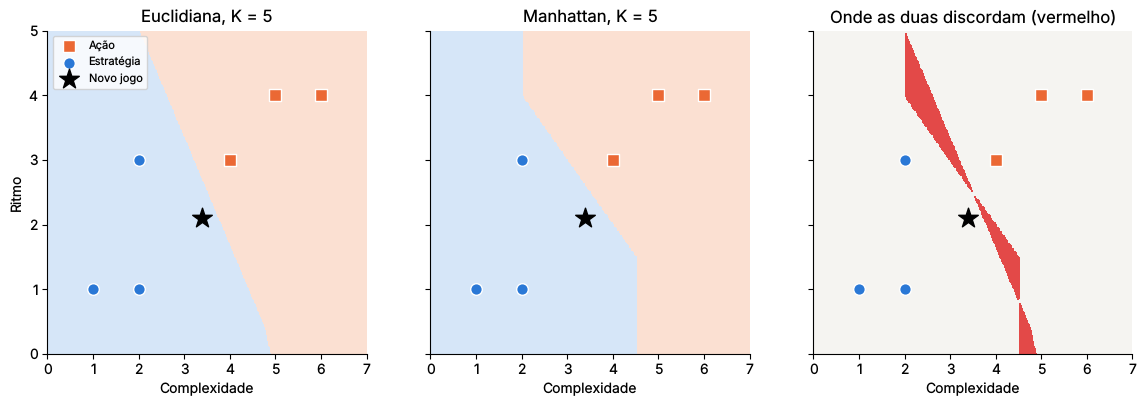

In [17]:
# Onde exatamente as métricas discordam (K = 5)
k = 5
euclid = prever_grade(n_neighbors=k, metric='euclidean').reshape(xx.shape)
manhat = prever_grade(n_neighbors=k, metric='manhattan').reshape(xx.shape)
from matplotlib.colors import ListedColormap
fundo = ListedColormap(['#fbe0d2', '#d6e6f8'])   # Ação, Estratégia (claros)

fig, eixos = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for eixo, (titulo, regiao) in zip(eixos[:2], [('Euclidiana', euclid), ('Manhattan', manhat)]):
    eixo.contourf(xx, yy, (regiao == 'Estratégia').astype(int), levels=[-0.5, 0.5, 1.5],
                  cmap=fundo)
    eixo.set_title(f'{titulo}, K = {k}')
eixos[2].contourf(xx, yy, (euclid != manhat).astype(int), levels=[-0.5, 0.5, 1.5],
                  colors=['#f5f4f1', '#e34948'])
eixos[2].set_title('Onde as duas discordam (vermelho)')
for eixo in eixos:
    for categoria, grupo in jogos.groupby('categoria'):
        eixo.scatter(grupo['complexidade'], grupo['ritmo'], s=70, color=CORES_CATEGORIA[categoria],
                     marker='o' if categoria == 'Estratégia' else 's', edgecolor='white',
                     zorder=3, label=categoria)
    eixo.scatter(*novo_jogo, marker='*', s=220, color='black', zorder=4, label='Novo jogo')
    eixo.set_xlabel('Complexidade')
    eixo.grid(False)
eixos[0].set_ylabel('Ritmo')
eixos[0].legend(loc='upper left', fontsize=8)
salvar(fig, 'atividade6_regioes')
plt.show()

**Interpretação — Atividade 6**

**Para o jogo novo, nenhuma configuração de métrica ou de peso mudou a previsão:** K=1 dá sempre Ação, e K=3 e K=5 dão sempre Estratégia. Quem muda a resposta é **K**, não a métrica nem o peso. Com `weights='distance'`, por exemplo, K=3 continua em Estratégia porque os pesos de J3 e J2 somados (1/1,664 + 1/1,780 ≈ 1,16) ainda superam o de J4 (1/1,082 ≈ 0,92). O que muda é a **confiança** — a coluna `P(Estratégia)` varia entre as configurações mesmo quando a classe final é a mesma.

**Isso não significa que esses parâmetros não tenham efeito.** Basta olhar para o plano inteiro: euclidiana e Manhattan discordam em **2 a 4% da área**, e `uniform` e `distance` em até **1,5%**. As discordâncias ficam todas **perto da fronteira** entre as classes, como mostra o mapa em vermelho — exatamente a região dos casos ambíguos. O jogo novo apenas não caiu numa delas.

Dois detalhes que a tabela confirma:

- com **K=1**, `uniform` e `distance` são **idênticos** (0% de diferença): com um vizinho só, não há o que ponderar;
- a conclusão "não mudou" vale **para este ponto, nesta base**. Em bases com mais atributos, escalas diferentes ou classes misturadas, a métrica e o peso podem mudar muitas previsões — por isso eles entram na busca de hiperparâmetros da seção 8, e não são escolhidos no olho.

## 7. Avaliação: como saber se o KNN realmente funciona?

Obter a categoria de um registro **não basta**. Precisamos verificar como o algoritmo se comporta com exemplos que ele **não recebeu no treinamento**.

- **Treinamento:** registros conhecidos usados pelo classificador.
- **Teste:** registros reservados para a avaliação final.
- **Acurácia:** proporção de previsões corretas. Não é a mesma coisa que a *precisão* da classe positiva.
- **Matriz de confusão:** mostra acertos e erros de cada classe.
- **Precisão, recall e F1-score:** ajudam a interpretar erros por categoria.

**Atenção:** escolher K observando repetidamente o conjunto de teste pode produzir uma avaliação otimista. A seleção de K deve usar um conjunto de validação ou validação cruzada realizada **dentro dos dados de treinamento**.

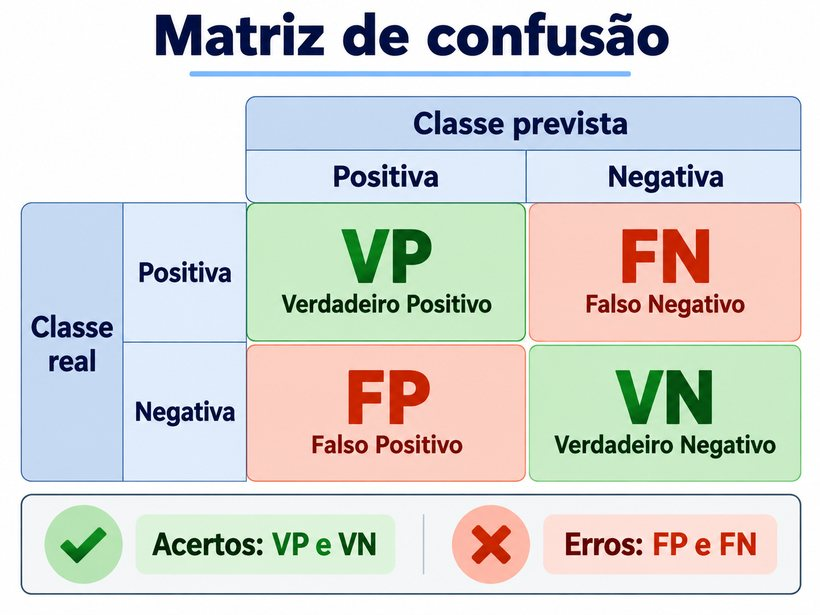

*Figura 3. VP e VN são acertos; FP e FN são erros.*

### 7.1 Exemplo completo com a base Iris (sem baixar CSV)

A base **Iris** contém **150 flores**, com **quatro medidas** cada uma e **três espécies**:

| Código | Espécie |
|---:|---|
| 0 | Setosa |
| 1 | Versicolor |
| 2 | Virginica |

A tarefa é **prever a espécie de uma flor a partir das suas medidas**, uma classificação com três classes.

**O que faremos:** carregamento → treino/teste → padronização no pipeline → ajuste → previsão → métricas.

In [18]:
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

iris = load_iris(as_frame=True)
X_iris = iris.data                 # Quatro atributos numéricos
y_iris = iris.target               # Classe de cada flor

print('Atributos:',list(X_iris.columns))
print('Classes:',list(iris.target_names))
print('Dimensões da base:',X_iris.shape)
display(X_iris.head())

Atributos: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Dimensões da base: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [19]:
# 1. Dividir os dados: 75% treino, 25% teste
X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_iris, test_size=0.25, random_state=123, stratify=y_iris
)

# 2. Construir pipeline: escalonamento e KNN
clf = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

# 3. Treinar e prever
clf.fit(X_train,y_train)
y_pred = clf.predict(X_test)

# 4. Avaliar
print('Acurácia (treino):',round(clf.score(X_train,y_train),3))
print('Acurácia (teste):',round(accuracy_score(y_test,y_pred),3))
print()
print('Relatório por classe:')
print(classification_report(y_test,y_pred,target_names=iris.target_names))

Acurácia (treino): 0.955
Acurácia (teste): 0.947

Relatório por classe:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.92      0.92      0.92        13
   virginica       0.92      0.92      0.92        13

    accuracy                           0.95        38
   macro avg       0.95      0.95      0.95        38
weighted avg       0.95      0.95      0.95        38



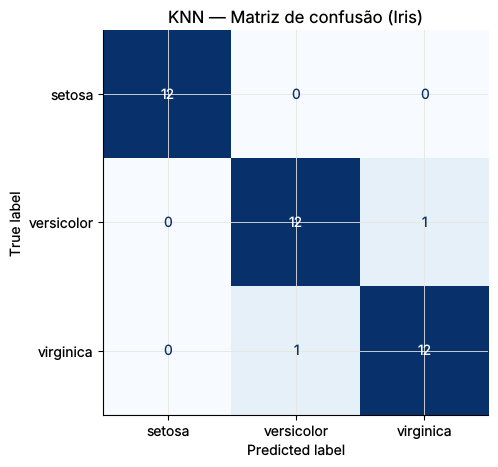

In [20]:
# Visualização da matriz de confusão
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,y_pred,display_labels=iris.target_names,cmap='Blues',ax=ax,
    colorbar=False
)
ax.set_title('KNN — Matriz de confusão (Iris)')
plt.show()

### ✍️ Atividade 7 — Interpretar as métricas

Com os resultados do Iris, responda: (a) qual foi a acurácia no teste? (b) qual espécie teve mais erros? (c) a acurácia de treino é igual à de teste? (d) por que a matriz de confusão é útil além da acurácia?

**Registre também sua interpretação em uma célula de texto.**

In [21]:
# ATIVIDADE 7: solução
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(y_test, y_pred)
erros = pd.DataFrame({
    'espécie': iris.target_names,
    'flores no teste': matriz.sum(axis=1),
    'acertos': np.diag(matriz),
    'erros': matriz.sum(axis=1) - np.diag(matriz),
})
erros['recall'] = (erros['acertos'] / erros['flores no teste']).round(3)

print(f"(a) Acurácia de teste: {accuracy_score(y_test, y_pred):.3f} "
      f"({int(np.trace(matriz))} de {len(y_test)} flores)")
print("(b) Erros por espécie:")
display(erros)
for i, real in enumerate(iris.target_names):
    for j, prevista in enumerate(iris.target_names):
        if i != j and matriz[i, j]:
            print(f"    {matriz[i, j]} {real} classificada(s) como {prevista}")
print(f"(c) Acurácia de treino: {clf.score(X_train, y_train):.3f} | "
      f"teste: {clf.score(X_test, y_test):.3f} | diferença: "
      f"{clf.score(X_train, y_train) - clf.score(X_test, y_test):+.3f}")
print(f"    No teste, cada flor vale {100 / len(y_test):.1f} pontos percentuais de acurácia.")

(a) Acurácia de teste: 0.947 (36 de 38 flores)
(b) Erros por espécie:


,espécie,flores no teste,acertos,erros,recall
0,setosa,12,12,0,1.000
1,versicolor,13,12,1,0.923
2,virginica,13,12,1,0.923


    1 versicolor classificada(s) como virginica
    1 virginica classificada(s) como versicolor
(c) Acurácia de treino: 0.955 | teste: 0.947 | diferença: +0.008
    No teste, cada flor vale 2.6 pontos percentuais de acurácia.


**Interpretação — Atividade 7**

**(a)** A acurácia no teste foi **0,947**: **36 de 38** flores classificadas corretamente.

**(b)** Não há uma espécie com mais erros: **versicolor e virginica empataram, com um erro cada**, e foram confundidas **uma com a outra** (uma versicolor prevista como virginica e uma virginica prevista como versicolor). A **setosa** não teve nenhum erro. Isso faz sentido com a biologia da base: a setosa tem pétalas bem menores e fica isolada das outras duas, enquanto versicolor e virginica se sobrepõem nas medidas.

**(c)** Não. A acurácia de treino foi **0,955** e a de teste **0,947** — muito próximas, o que indica que o modelo **não está decorando** o treino. A diferença equivale a menos de uma flor: com 38 flores no teste, **cada flor vale 2,6 pontos percentuais**, então variações dessa ordem são ruído.

**(d)** A acurácia resume tudo em um número e esconde **onde** estão os erros. A matriz mostra que o problema está todo na fronteira **versicolor × virginica** e que a setosa é trivial. Em problemas com classes desbalanceadas isso é ainda mais importante: um modelo pode ter acurácia alta acertando só a classe majoritária, e só a matriz (e o recall por classe) revela isso.

### ✍️ Atividade 8 — A influência de K na generalização

Treine modelos com **K = 1, 3, 5, 7, 9, 11 e 15**. Construa uma tabela e um gráfico com **acurácia de treinamento** e **acurácia de teste**. Identifique um valor de K com desempenho equilibrado. **Neste exercício exploratório, não trate o K escolhido por olhar o teste como resultado final imparcial.**

**Registre também sua interpretação em uma célula de texto.**

,K,acurácia treino,acurácia teste,diferença (treino - teste)
0,1,1.000,1.000,0.000
1,3,0.946,0.974,-0.027
2,5,0.955,0.947,0.008
3,7,0.955,0.974,-0.018
4,9,0.955,0.974,-0.018
5,11,0.955,1.000,-0.045
6,15,0.946,0.974,-0.027


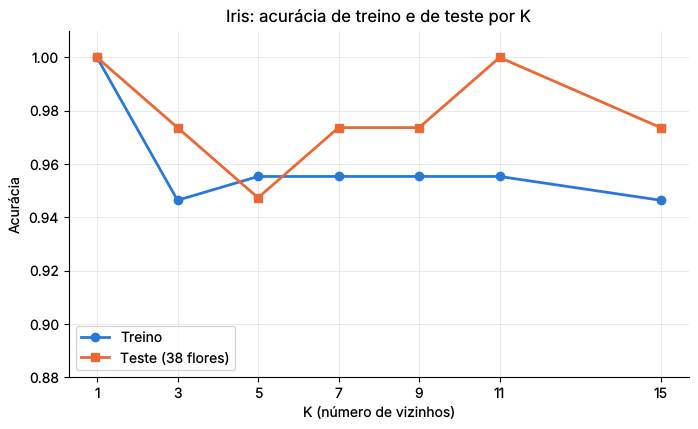

In [22]:
# ATIVIDADE 8: solução

valores_k = [1, 3, 5, 7, 9, 11, 15]
linhas = []
for k in valores_k:
    modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train)
    linhas.append({'K': k,
                   'acurácia treino': modelo.score(X_train, y_train),
                   'acurácia teste': modelo.score(X_test, y_test)})
curva_k = pd.DataFrame(linhas)
curva_k['diferença (treino - teste)'] = curva_k['acurácia treino'] - curva_k['acurácia teste']
display(curva_k.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curva_k['K'], curva_k['acurácia treino'], marker='o', linewidth=2,
        color=COR_TREINO, label='Treino')
ax.plot(curva_k['K'], curva_k['acurácia teste'], marker='s', linewidth=2,
        color=COR_TESTE, label='Teste (38 flores)')
ax.set_xticks(valores_k)
ax.set_xlabel('K (número de vizinhos)')
ax.set_ylabel('Acurácia')
ax.set_ylim(0.88, 1.01)
ax.set_title('Iris: acurácia de treino e de teste por K')
ax.legend()
salvar(fig, 'atividade8_curva_k')
plt.show()

**Interpretação — Atividade 8**

**K=1** tem acurácia de treino **1,000** — e isso é inevitável, não mérito: cada flor de treino é a vizinha mais próxima de si mesma, então o modelo apenas reconhece o que já viu. É o sinal clássico de memorização. Neste teste específico o K=1 também acertou as 38 flores, mas isso diz mais sobre o tamanho do teste do que sobre o modelo.

A partir de **K=3** a acurácia de treino estabiliza em torno de **0,95**, sem decorar, e a de teste oscila entre **0,947 e 1,000**. Um valor equilibrado seria **K=7 ou K=9**: treino 0,955, teste 0,974, diferença pequena e nenhum sinal de memorização.

Mas é preciso ler o gráfico com cautela. **O teste tem só 38 flores**, e cada uma vale 2,6 pontos: o "zigue-zague" entre 0,947, 0,974 e 1,000 é, literalmente, **uma flor a mais ou a menos**. Escolher K pelo ponto mais alto dessa curva seria escolher pelo acaso do sorteio — e, pior, usaria o teste para decidir, contaminando a avaliação final. É exatamente por isso que a seção 8 escolhe K com **validação cruzada dentro do treino**.

## 8. Encontrando K com validação cruzada

Em lugar de escolher K por tentativa e erro no conjunto de teste, podemos usar **validação cruzada nos dados de treinamento**. Assim, os mesmos registros de treinamento são reorganizados em diferentes divisões internas.

Observe que há **dois valores diferentes**:

- `n_neighbors`: número de vizinhos utilizados pelo KNN.
- `n_splits`: número de partições (folds) da validação cruzada.

Eles não são o mesmo parâmetro.

Vamos experimentar K de 1 a 15, com **5 folds estratificados**, mantendo o escalonador dentro do pipeline.

In [23]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())

parametros = {
    'kneighborsclassifier__n_neighbors': [1,3,5,7,9,11,13,15],
    'kneighborsclassifier__weights': ['uniform','distance'],
    'kneighborsclassifier__p': [1,2]
}

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=123)
busca = GridSearchCV(pipe,parametros,cv=cv,scoring='accuracy',n_jobs=-1)
busca.fit(X_train,y_train)

print('Melhores parâmetros:',busca.best_params_)
print('Acurácia média na validação:',round(busca.best_score_,3))
print('Acurácia final no teste reservado:',round(busca.score(X_test,y_test),3))

Melhores parâmetros: {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__p': 2, 'kneighborsclassifier__weights': 'distance'}
Acurácia média na validação: 0.956
Acurácia final no teste reservado: 0.974


### ✍️ Atividade 9 — Pesquisando hiperparâmetros

Amplie a lista de `n_neighbors` para incluir **17, 19 e 21**. Compare o melhor K e a acurácia média da validação cruzada. A acurácia do teste deve ser usada para escolher hiperparâmetros?

**Registre também sua interpretação em uma célula de texto.**

,grade,melhores parâmetros,acurácia média CV
0,K de 1 a 15,"{'kneighborsclassifier__n_neighbors': 15, 'kne...",0.9557
1,K de 1 a 21,"{'kneighborsclassifier__n_neighbors': 15, 'kne...",0.9557


As 8 melhores combinações da grade ampliada:


,n_neighbors,weights,p,mean_test_score,std_test_score,rank_test_score
31,15,distance,2,0.9557,0.0275,1
35,17,distance,2,0.9557,0.0275,1
12,7,uniform,1,0.9553,0.0398,3
13,7,distance,1,0.9553,0.0398,3
20,11,uniform,1,0.9553,0.0398,3
21,11,distance,1,0.9553,0.0398,3
25,13,distance,1,0.9553,0.0398,3
27,13,distance,2,0.9553,0.0398,3


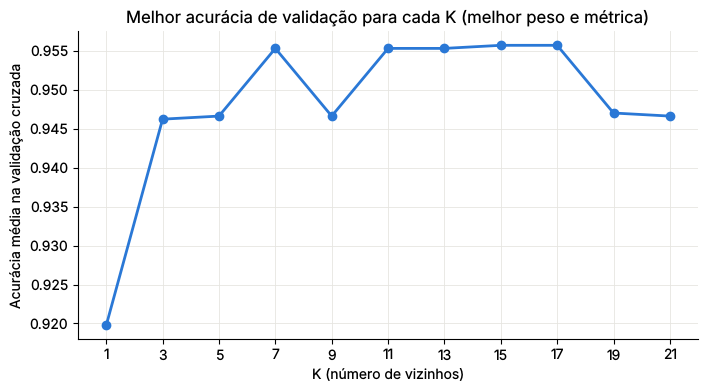

In [24]:
# ATIVIDADE 9: solução

parametros_ampliados = {**parametros,
    'kneighborsclassifier__n_neighbors': [1,3,5,7,9,11,13,15,17,19,21]}
busca_ampliada = GridSearchCV(pipe, parametros_ampliados, cv=cv, scoring='accuracy', n_jobs=-1)
busca_ampliada.fit(X_train, y_train)

comparacao9 = pd.DataFrame([
    {'grade': 'K de 1 a 15', 'melhores parâmetros': busca.best_params_,
     'acurácia média CV': round(busca.best_score_, 4)},
    {'grade': 'K de 1 a 21', 'melhores parâmetros': busca_ampliada.best_params_,
     'acurácia média CV': round(busca_ampliada.best_score_, 4)},
])
display(comparacao9)

resultados_cv = pd.DataFrame(busca_ampliada.cv_results_)
topo = (resultados_cv.sort_values(['rank_test_score', 'param_kneighborsclassifier__n_neighbors'])
        [['param_kneighborsclassifier__n_neighbors', 'param_kneighborsclassifier__weights',
          'param_kneighborsclassifier__p', 'mean_test_score', 'std_test_score', 'rank_test_score']]
        .head(8).rename(columns=lambda c: c.replace('param_kneighborsclassifier__', '')))
print('As 8 melhores combinações da grade ampliada:')
display(topo.round(4))

melhor_por_k = (resultados_cv.groupby('param_kneighborsclassifier__n_neighbors')
                ['mean_test_score'].max())
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(melhor_por_k.index, melhor_por_k.values, marker='o', linewidth=2, color=COR_TREINO)
ax.set_xticks(melhor_por_k.index)
ax.set_xlabel('K (número de vizinhos)')
ax.set_ylabel('Acurácia média na validação cruzada')
ax.set_title('Melhor acurácia de validação para cada K (melhor peso e métrica)')
salvar(fig, 'atividade9_validacao')
plt.show()

**Interpretação — Atividade 9**

Ampliar a grade **não mudou o modelo escolhido**: nas duas buscas o melhor foi **K=15, `weights='distance'`, `p=2` (euclidiana)**, com acurácia média de validação de **0,956**. Com a grade ampliada, **K=17** aparece **empatado** com K=15 exatamente na mesma média — o `GridSearchCV` desempata pela ordem da grade e fica com o primeiro. Os valores 19 e 21 já começam a piorar.

O mais importante, porém, é o formato da curva: **de K=3 a K=21 a melhor validação de cada K fica entre 0,946 e 0,956** — uma faixa de cerca de 1 ponto percentual, o equivalente a uma flor na média dos folds — e K=7, 11, 13, 15 e 17 ficam todos entre 0,955 e 0,956. A diferença entre o "melhor" e vários outros está na **quarta casa decimal**, enquanto o desvio-padrão entre os folds é de cerca de **0,03 a 0,04**. Ou seja, não há um K claramente superior nesse intervalo — qualquer um deles é uma escolha defensável, e na dúvida o mais simples serve.

Vale notar também que o melhor K da grade original (15) estava **na borda** da lista testada. Quando o ótimo cai na borda, é sinal de que vale ampliar a busca — que é justamente o que esta atividade pede. Aqui a ampliação mostrou que não havia nada melhor além dela.

**A acurácia do teste deve ser usada para escolher hiperparâmetros? Não.** O teste deve ser usado **uma única vez**, depois de todas as escolhas feitas. Se ele participar da escolha, deixa de medir desempenho em dados novos e passa a ser mais um conjunto de ajuste — a avaliação fica otimista. A validação cruzada existe justamente para fazer a escolha **dentro do treino**.

## 9. Estudo de caso: Titanic — comparando KNN com Random Forest

No material da aula anterior, o conjunto Titanic foi utilizado com Random Forest. Agora faremos a mesma tarefa de classificação utilizando KNN: prever, apenas para fins didáticos, o campo `survived` (0 = não sobreviveu; 1 = sobreviveu) a partir de algumas características dos passageiros.

**Atributos escolhidos, alinhados à aula anterior:**

| Atributo | Significado |
|---|---|
| `pclass` | classe de passagem (1, 2 ou 3) |
| `female` | sexo registrado convertido em 0/1 para a experiência |
| `age` | idade |
| `fare` | valor pago pela passagem |
| `survived` | rótulo que queremos prever (0/1) |

**Atenção:** `sns.load_dataset('titanic')` pode precisar de acesso à internet na primeira execução no Colab. Se não houver conexão, continue com a base Iris, que já está incluída no Scikit-learn. Para uma comparação justa entre algoritmos, eles devem usar o mesmo particionamento e as mesmas variáveis; procedimentos de pré-processamento podem variar entre algoritmos.

Há duas particularidades metodológicas: `pclass` é uma categoria ordinal e `female` é binária; por simplicidade didática, neste experimento inicial elas serão tratadas como numéricas. Em análises mais criteriosas, avalie codificações e métricas apropriadas a atributos mistos.

In [25]:
# O exemplo Titanic pode exigir internet na primeira execução
import seaborn as sns

titanic = sns.load_dataset('titanic')
titanic['female'] = titanic['sex'].map({'male':0,'female':1})
atributos = ['pclass','female','age','fare']

# Mantendo o mesmo conjunto de atributos da aula anterior
base_titanic = titanic.dropna(subset=atributos+['survived']).copy()
X_titanic = base_titanic[atributos]
y_titanic = base_titanic['survived']

print('Exemplos válidos:',len(base_titanic))
print('Proporção de sobrevivência:',round(y_titanic.mean(),3))
display(base_titanic[atributos+['survived']].head())

Exemplos válidos: 714
Proporção de sobrevivência: 0.406


,pclass,female,age,fare,survived
0,3,0,22.0,7.2500,0
1,1,1,38.0,71.2833,1
2,3,1,26.0,7.9250,1
3,1,1,35.0,53.1000,1
4,3,0,35.0,8.0500,0


Acurácia de treino: 0.856
Acurácia de teste: 0.816
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       108
           1       0.80      0.72      0.76        71

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



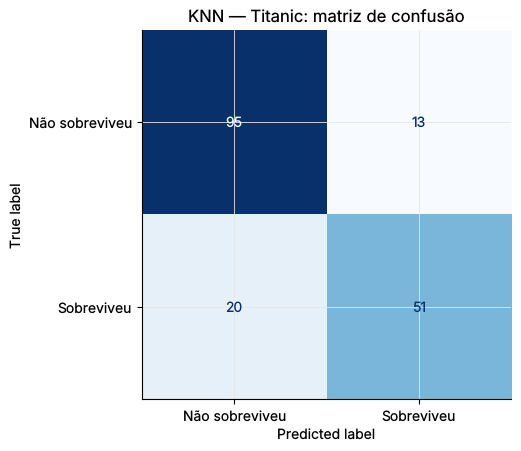

In [26]:
# Mesmo random_state e test_size apresentados na aula de Random Forest
Xtr_t, Xte_t, ytr_t, yte_t = train_test_split(
    X_titanic, y_titanic, test_size=0.25, random_state=123
)

# No PDF da aula a linha abaixo aparece cortada; K=5 é o valor usado nos demais exemplos
knn_titanic = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_titanic.fit(Xtr_t,ytr_t)
previsoes = knn_titanic.predict(Xte_t)

print('Acurácia de treino:',round(knn_titanic.score(Xtr_t,ytr_t),3))
print('Acurácia de teste:',round(accuracy_score(yte_t,previsoes),3))
print(classification_report(yte_t,previsoes,zero_division=0))

ConfusionMatrixDisplay.from_predictions(yte_t,previsoes,
    display_labels=['Não sobreviveu','Sobreviveu'],cmap='Blues',colorbar=False)
plt.title('KNN — Titanic: matriz de confusão')
plt.show()

### ✍️ Atividade 10 — Comparação com Random Forest

Com o mesmo particionamento do Titanic, treine um `RandomForestClassifier(n_estimators=100, random_state=123)`. Compare a acurácia de teste e a matriz de confusão com o KNN. Qual apresentou melhor desempenho nesta divisão? Isso garante superioridade em outros dados?

**Registre também sua interpretação em uma célula de texto.**

,modelo,acurácia treino,acurácia teste,acertos (de 179),recall não sobreviveu,recall sobreviveu
0,"KNN (K=5, padronizado)",0.856,0.816,146,0.880,0.718
1,Random Forest (100 árvores),0.989,0.810,145,0.861,0.732


No teste há 179 passageiros: cada um vale 0.56 pontos percentuais.


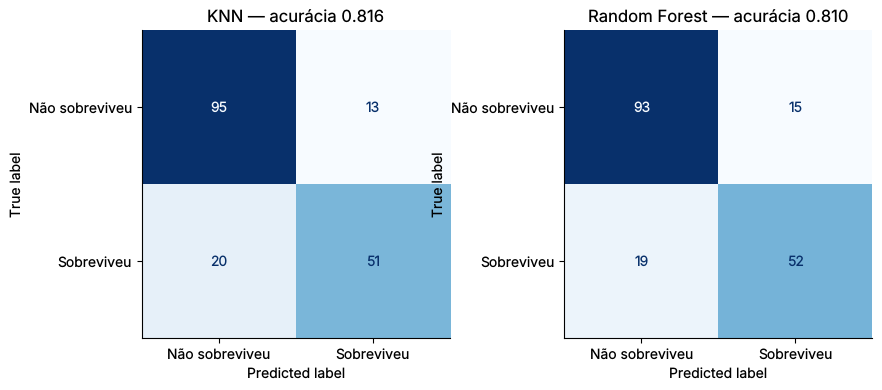

In [27]:
# ATIVIDADE 10: solução
from sklearn.ensemble import RandomForestClassifier

floresta = RandomForestClassifier(n_estimators=100, random_state=123)
floresta.fit(Xtr_t, ytr_t)                 # mesmo particionamento do KNN
previsoes_rf = floresta.predict(Xte_t)

nomes_titanic = ['Não sobreviveu', 'Sobreviveu']
linhas = []
for nome, modelo, prev in [('KNN (K=5, padronizado)', knn_titanic, previsoes),
                           ('Random Forest (100 árvores)', floresta, previsoes_rf)]:
    matriz = confusion_matrix(yte_t, prev)
    linhas.append({'modelo': nome,
                   'acurácia treino': modelo.score(Xtr_t, ytr_t),
                   'acurácia teste': accuracy_score(yte_t, prev),
                   'acertos (de %d)' % len(yte_t): int(np.trace(matriz)),
                   'recall não sobreviveu': matriz[0, 0] / matriz[0].sum(),
                   'recall sobreviveu': matriz[1, 1] / matriz[1].sum()})
comparacao10 = pd.DataFrame(linhas)
display(comparacao10.round(3))
print(f'No teste há {len(yte_t)} passageiros: cada um vale {100 / len(yte_t):.2f} pontos percentuais.')

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for eixo, (nome, prev) in zip(eixos, [('KNN', previsoes), ('Random Forest', previsoes_rf)]):
    ConfusionMatrixDisplay.from_predictions(yte_t, prev, display_labels=nomes_titanic,
                                            cmap='Blues', colorbar=False, ax=eixo)
    eixo.set_title(f'{nome} — acurácia {accuracy_score(yte_t, prev):.3f}')
    eixo.grid(False)
salvar(fig, 'atividade10_matrizes')
plt.show()

        KNN  Random Forest  RF - KNN
mean  0.806          0.806    -0.000
std   0.022          0.024     0.024
min   0.760          0.737    -0.056
max   0.866          0.849     0.073

Random Forest melhor em 15 sorteios, KNN melhor em 12, empate em 3.


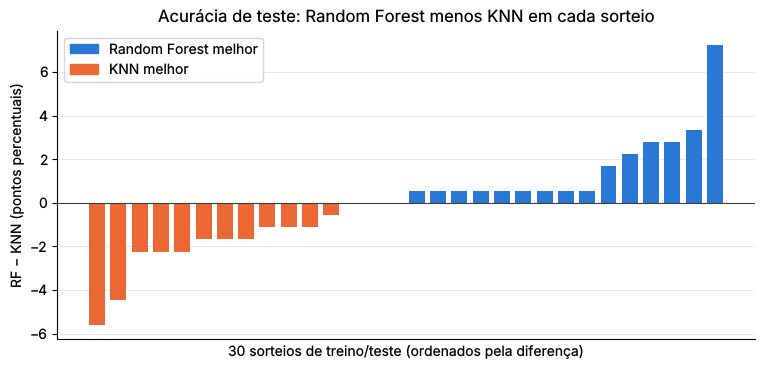

In [28]:
# Isso garante superioridade? Repetindo a mesma comparação em 30 sorteios diferentes
linhas = []
for semente in range(30):
    a_tr, a_te, b_tr, b_te = train_test_split(X_titanic, y_titanic, test_size=0.25,
                                              random_state=semente)
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(a_tr, b_tr)
    rf = RandomForestClassifier(n_estimators=100, random_state=123).fit(a_tr, b_tr)
    linhas.append({'random_state': semente, 'KNN': knn.score(a_te, b_te),
                   'Random Forest': rf.score(a_te, b_te)})
sorteios = pd.DataFrame(linhas)
sorteios['RF - KNN'] = sorteios['Random Forest'] - sorteios['KNN']

print(sorteios[['KNN', 'Random Forest', 'RF - KNN']].describe().loc[['mean', 'std', 'min', 'max']].round(3))
print(f"\nRandom Forest melhor em {(sorteios['RF - KNN'] > 0).sum()} sorteios, "
      f"KNN melhor em {(sorteios['RF - KNN'] < 0).sum()}, empate em {(sorteios['RF - KNN'] == 0).sum()}.")

ordenado = sorteios.sort_values('RF - KNN').reset_index(drop=True)
cores = np.where(ordenado['RF - KNN'] > 0, COR_ESTRATEGIA, np.where(ordenado['RF - KNN'] < 0, COR_ACAO, '#8a8984'))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(ordenado.index, 100 * ordenado['RF - KNN'], color=cores, width=0.75)
ax.axhline(0, color='#3d3c38', linewidth=0.8)
ax.set_xticks([])
ax.set_xlabel('30 sorteios de treino/teste (ordenados pela diferença)')
ax.set_ylabel('RF − KNN (pontos percentuais)')
ax.set_title('Acurácia de teste: Random Forest menos KNN em cada sorteio')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COR_ESTRATEGIA, label='Random Forest melhor'),
                   Patch(color=COR_ACAO, label='KNN melhor')], loc='upper left')
salvar(fig, 'atividade10_sorteios')
plt.show()

**Interpretação — Atividade 10**

**Nesta divisão (`random_state=123`), o KNN foi ligeiramente melhor: 0,816 contra 0,810 de acurácia de teste.** A diferença é de **um único passageiro** em 179 (146 × 145 acertos) — cada passageiro vale 0,56 ponto percentual.

As matrizes mostram que os dois erram de formas um pouco diferentes. O KNN acerta mais quem **não sobreviveu** (95 de 108, contra 93) e o Random Forest acerta mais quem **sobreviveu** (52 de 71, contra 51). Os dois têm mais dificuldade com a classe "sobreviveu", que é minoritária (40,6% da base): o recall dela fica em 0,72–0,73, enquanto o da outra classe fica entre 0,86 e 0,88.

Há também uma diferença importante entre treino e teste. O Random Forest tem acurácia de treino **0,989** e o KNN **0,856**: a floresta praticamente decora o treino, mas isso **não** se converte em melhor desempenho no teste.

**Isso garante superioridade em outros dados? Não.** Repetindo exatamente a mesma comparação em **30 sorteios** diferentes de treino e teste, o Random Forest foi melhor em **15**, o KNN em **12** e houve **3 empates**. A diferença média é **praticamente zero** (−0,02 ponto), e a diferença em um sorteio isolado varia de **−5,6 a +7,3 pontos**. O "vencedor" da divisão 123 é, portanto, um resultado do sorteio, e não uma propriedade dos algoritmos. Para afirmar que um é melhor, seria preciso validação cruzada ou repetição dos sorteios — e, mesmo assim, só para esta base, estes atributos e estes hiperparâmetros.

## 10. Atividade avaliativa — KNN com a base Iris

**Enunciado:** Desenvolva, no Google Colab, um experimento de classificação de espécies de Iris usando o algoritmo KNN. Utilize os quatro atributos disponíveis, divida os dados em treinamento e teste e avalie o modelo de modo reproduzível.

**Tarefas obrigatórias:**

1. Carregue a base Iris e explique o significado das quatro variáveis e da classe-alvo.
2. Separe 75% dos registros para treino e 25% para teste com `random_state=123` e `stratify=y`.
3. Crie um `Pipeline` contendo `StandardScaler` e `KNeighborsClassifier`.
4. Treine modelos para K=1, 3, 5, 7, 9, 11 e 15 e gere uma tabela comparativa de acurácia de treino.
5. Utilize validação cruzada com 5 folds para selecionar os parâmetros a partir somente do treinamento.
6. Avalie uma vez o melhor modelo no conjunto de teste: acurácia, precisão, recall, F1-score e matriz de confusão.
7. Compare pesos uniformes versus pesos proporcionais à distância e distância euclidiana versus Manhattan.
8. Compare os resultados com os de uma Árvore de Decisão, usando o mesmo particionamento.
9. Escreva uma conclusão discutindo desempenho, sensibilidade a K, normalização, limitações e generalização.

**Entrega:** notebook `.ipynb` e um breve relatório em PDF com os resultados, gráficos e interpretação. A avaliação não deve se limitar a mostrar uma acurácia numérica.

### ✍️ Atividade 11 — Monte seu experimento final

Execute as etapas do enunciado acima e crie um DataFrame que reúna os resultados das diferentes configurações. Inclua pelo menos um gráfico e a matriz de confusão.

**Registre também sua interpretação em uma célula de texto.**

#### Etapa 1 — A base Iris e suas variáveis

In [29]:
# ATIVIDADE 11: solução
# Etapa 1: carregar a base e descrever as variáveis
iris = load_iris(as_frame=True)
X_iris, y_iris = iris.data, iris.target
especies = list(iris.target_names)

dicionario = pd.DataFrame({
    'variável': X_iris.columns,
    'significado': ['comprimento da sépala', 'largura da sépala',
                    'comprimento da pétala', 'largura da pétala'],
    'unidade': 'cm',
    'mínimo': X_iris.min().values,
    'máximo': X_iris.max().values,
    'média': X_iris.mean().values,
    'desvio-padrão': X_iris.std().values,
})
display(dicionario.round(2))

print('Classe-alvo: espécie da flor')
display(pd.DataFrame({'código': range(3), 'espécie': especies,
                      'flores': y_iris.value_counts().sort_index().values}))

print('Média de cada medida por espécie (cm):')
display(X_iris.groupby(y_iris.map(dict(enumerate(especies))).rename('espécie')).mean().round(2))

,variável,significado,unidade,mínimo,máximo,média,desvio-padrão
0,sepal length (cm),comprimento da sépala,cm,4.3,7.9,5.84,0.83
1,sepal width (cm),largura da sépala,cm,2.0,4.4,3.06,0.44
2,petal length (cm),comprimento da pétala,cm,1.0,6.9,3.76,1.77
3,petal width (cm),largura da pétala,cm,0.1,2.5,1.20,0.76


Classe-alvo: espécie da flor


,código,espécie,flores
0,0,setosa,50
1,1,versicolor,50
2,2,virginica,50


Média de cada medida por espécie (cm):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
espécie,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


As **quatro variáveis** são medidas, em centímetros, de duas partes da flor:

- **sépala** (`sepal length`, `sepal width`): as folhas externas, geralmente verdes, que protegem o botão antes de a flor abrir;
- **pétala** (`petal length`, `petal width`): as folhas internas e coloridas da flor.

A **classe-alvo** (`target`) é a **espécie**: 0 = *setosa*, 1 = *versicolor*, 2 = *virginica*, com **50 flores de cada** — uma base balanceada. A tabela de médias já antecipa o resultado: as medidas da **pétala** separam muito bem as espécies (comprimento médio de 1,46 cm na setosa, 4,26 na versicolor e 5,55 na virginica), enquanto as da sépala se sobrepõem bem mais. As quatro variáveis estão na mesma unidade, mas não na mesma escala: o desvio-padrão vai de 0,44 cm (largura da sépala) a 1,77 cm (comprimento da pétala).

#### Etapas 2 e 3 — Separação treino/teste e pipeline

In [30]:
# Etapa 2: 75% treino, 25% teste, estratificado e reproduzível
Xi_treino, Xi_teste, yi_treino, yi_teste = train_test_split(
    X_iris, y_iris, test_size=0.25, random_state=123, stratify=y_iris)

contagem = pd.DataFrame({'treino': yi_treino.value_counts().sort_index().values,
                         'teste': yi_teste.value_counts().sort_index().values}, index=especies)
print(f'Treino: {len(Xi_treino)} flores | Teste: {len(Xi_teste)} flores')
display(contagem)

# Etapa 3: o StandardScaler fica DENTRO do pipeline, então só aprende com o treino
from sklearn.pipeline import Pipeline
modelo_knn = Pipeline([('padronizacao', StandardScaler()),
                       ('knn', KNeighborsClassifier())])
print(modelo_knn)

Treino: 112 flores | Teste: 38 flores


,treino,teste
setosa,38,12
versicolor,37,13
virginica,37,13


Pipeline(steps=[('padronizacao', StandardScaler()),
                ('knn', KNeighborsClassifier())])


#### Etapa 4 — Acurácia de treino para cada K

Além da acurácia de treino pedida no enunciado, a tabela traz a acurácia de **validação cruzada (5 folds) dentro do treino**: ela mostra como cada K se sai em dados que o modelo não viu, **sem tocar no teste**.

,K,acurácia treino,acurácia CV (média),acurácia CV (desvio)
0,1,1.000,0.920,0.034
1,3,0.946,0.946,0.052
2,5,0.955,0.938,0.045
3,7,0.955,0.947,0.033
4,9,0.955,0.946,0.034
5,11,0.955,0.938,0.036
6,15,0.946,0.929,0.044


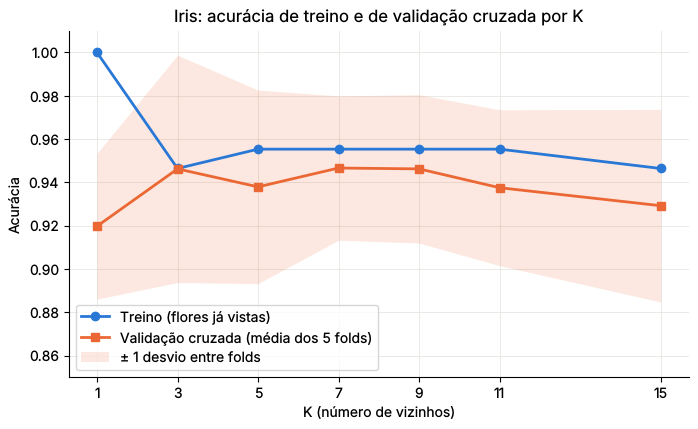

In [31]:
# Etapa 4: K = 1, 3, 5, 7, 9, 11 e 15
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

cv_aval = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
valores_k = [1, 3, 5, 7, 9, 11, 15]

linhas = []
for k in valores_k:
    modelo = clone(modelo_knn).set_params(knn__n_neighbors=k)
    notas = cross_val_score(modelo, Xi_treino, yi_treino, cv=cv_aval, scoring='accuracy')
    modelo.fit(Xi_treino, yi_treino)
    linhas.append({'K': k,
                   'acurácia treino': modelo.score(Xi_treino, yi_treino),
                   'acurácia CV (média)': notas.mean(),
                   'acurácia CV (desvio)': notas.std()})
tabela_k = pd.DataFrame(linhas)
display(tabela_k.round(3))
tabela_k.to_csv(PASTA_RESULTADOS / 'avaliativa_tabela_k.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tabela_k['K'], tabela_k['acurácia treino'], marker='o', linewidth=2,
        color=COR_TREINO, label='Treino (flores já vistas)')
ax.plot(tabela_k['K'], tabela_k['acurácia CV (média)'], marker='s', linewidth=2,
        color=COR_TESTE, label='Validação cruzada (média dos 5 folds)')
ax.fill_between(tabela_k['K'],
                tabela_k['acurácia CV (média)'] - tabela_k['acurácia CV (desvio)'],
                tabela_k['acurácia CV (média)'] + tabela_k['acurácia CV (desvio)'],
                color=COR_TESTE, alpha=0.15, linewidth=0, label='± 1 desvio entre folds')
ax.set_xticks(valores_k)
ax.set_xlabel('K (número de vizinhos)')
ax.set_ylabel('Acurácia')
ax.set_ylim(0.85, 1.01)
ax.set_title('Iris: acurácia de treino e de validação cruzada por K')
ax.legend(loc='lower left')
salvar(fig, 'avaliativa_curva_k')
plt.show()

#### Etapa 5 — Seleção dos parâmetros por validação cruzada (somente treino)

In [32]:
# Etapa 5: K, peso e métrica escolhidos juntos, com 5 folds dentro do treino
grade_parametros = {'knn__n_neighbors': valores_k,
                    'knn__weights': ['uniform', 'distance'],
                    'knn__p': [1, 2]}                     # p=1 Manhattan, p=2 euclidiana
busca_final = GridSearchCV(modelo_knn, grade_parametros, cv=cv_aval,
                           scoring='accuracy', n_jobs=-1)
busca_final.fit(Xi_treino, yi_treino)

resultados_grade = pd.DataFrame(busca_final.cv_results_).rename(
    columns=lambda c: c.replace('param_knn__', ''))
melhor = resultados_grade.loc[busca_final.best_index_]
print('Melhores parâmetros:', busca_final.best_params_)
print(f"Acurácia média na validação: {busca_final.best_score_:.4f} "
      f"(desvio entre folds: {melhor['std_test_score']:.3f})")

print('\nAs 8 melhores das', len(resultados_grade), 'combinações:')
display(resultados_grade.sort_values(['rank_test_score', 'n_neighbors'])
        [['n_neighbors', 'weights', 'p', 'mean_test_score', 'std_test_score', 'rank_test_score']]
        .head(8).round(4))
proximas = (resultados_grade['mean_test_score'] >= busca_final.best_score_ - 0.001).sum()
print(f'Combinações a menos de 0,001 da melhor: {proximas}')

Melhores parâmetros: {'knn__n_neighbors': 15, 'knn__p': 2, 'knn__weights': 'distance'}
Acurácia média na validação: 0.9557 (desvio entre folds: 0.028)

As 8 melhores das 28 combinações:


,n_neighbors,weights,p,mean_test_score,std_test_score,rank_test_score
27,15,distance,2,0.9557,0.0275,1
12,7,uniform,1,0.9553,0.0398,2
13,7,distance,1,0.9553,0.0398,2
20,11,uniform,1,0.9553,0.0398,2
21,11,distance,1,0.9553,0.0398,2
11,5,distance,2,0.9466,0.0333,6
14,7,uniform,2,0.9466,0.0333,6
15,7,distance,2,0.9466,0.0333,6


Combinações a menos de 0,001 da melhor: 5


#### Etapa 6 — Avaliação única do modelo escolhido no teste

Acurácia de teste: 0.974 (37 de 38 flores)
Precisão (macro): 0.976 | Recall (macro): 0.974 | F1 (macro): 0.974
Acurácia de treino: 1.000



,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12.0
versicolor,1.000,0.923,0.960,13.0
virginica,0.929,1.000,0.963,13.0
accuracy,NaN,NaN,0.974,38.0
macro avg,0.976,0.974,0.974,38.0
weighted avg,0.976,0.974,0.974,38.0


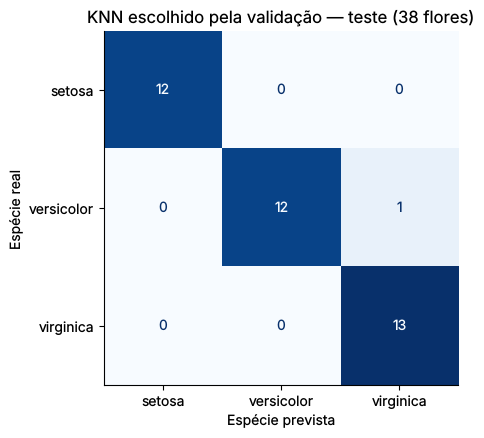

In [33]:
# Etapa 6: o teste é usado UMA vez, depois de todas as escolhas
from sklearn.metrics import precision_recall_fscore_support

modelo_final = busca_final.best_estimator_
yi_previsto = modelo_final.predict(Xi_teste)

acuracia_teste = accuracy_score(yi_teste, yi_previsto)
precisao, recall, f1, _ = precision_recall_fscore_support(yi_teste, yi_previsto, average='macro')
matriz_final = confusion_matrix(yi_teste, yi_previsto)

print(f'Acurácia de teste: {acuracia_teste:.3f} ({np.trace(matriz_final)} de {len(yi_teste)} flores)')
print(f'Precisão (macro): {precisao:.3f} | Recall (macro): {recall:.3f} | F1 (macro): {f1:.3f}')
print(f'Acurácia de treino: {modelo_final.score(Xi_treino, yi_treino):.3f}\n')

metricas_teste = (pd.DataFrame(classification_report(yi_teste, yi_previsto, target_names=especies,
                                                     output_dict=True)).T)
metricas_teste.loc['accuracy', ['precision', 'recall']] = np.nan   # linha de acurácia só tem um valor
metricas_teste.loc['accuracy', 'support'] = len(yi_teste)
display(metricas_teste.round(3))
metricas_teste.to_csv(PASTA_RESULTADOS / 'avaliativa_metricas_teste.csv')

fig, ax = plt.subplots(figsize=(5.5, 4.6))
ConfusionMatrixDisplay.from_predictions(yi_teste, yi_previsto, display_labels=especies,
                                        cmap='Blues', colorbar=False, ax=ax)
ax.set_title('KNN escolhido pela validação — teste (38 flores)')
ax.set_xlabel('Espécie prevista'); ax.set_ylabel('Espécie real')
ax.grid(False)
salvar(fig, 'avaliativa_matriz_confusao')
plt.show()

#### Etapa 7 — Pesos uniformes × distância e euclidiana × Manhattan

A comparação usa as notas de **validação cruzada** já calculadas na Etapa 5, ou seja, somente o treino.

variante,uniforme + euclidiana,distância + euclidiana,uniforme + Manhattan,distância + Manhattan
K,,,,
1,0.920,0.920,0.910,0.910
3,0.946,0.946,0.938,0.938
5,0.938,0.947,0.946,0.946
7,0.947,0.947,0.955,0.955
9,0.946,0.947,0.947,0.947
11,0.938,0.947,0.955,0.955
15,0.929,0.956,0.938,0.946


,comparação,diferença média (pontos),menor diferença (pontos),maior diferença (pontos),casos sem diferença
0,distância − uniforme,0.38,0.00,2.65,9 de 14
1,euclidiana − Manhattan,-0.11,-1.78,0.95,1 de 14


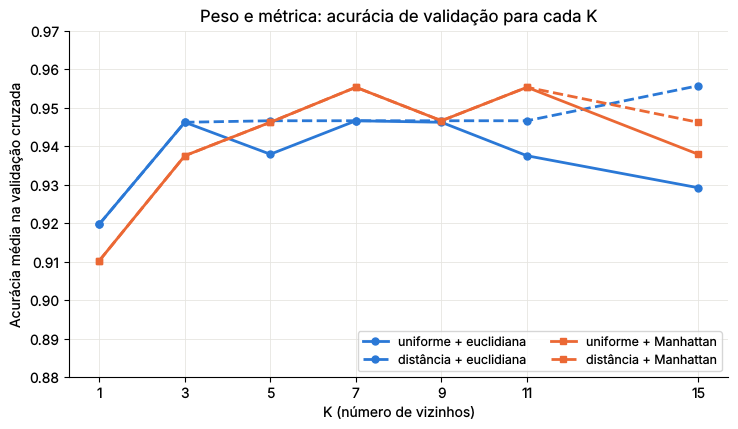

In [34]:
# Etapa 7: as quatro combinações de peso e métrica, para cada K
nomes_variante = {('uniform', 2): 'uniforme + euclidiana', ('distance', 2): 'distância + euclidiana',
                  ('uniform', 1): 'uniforme + Manhattan', ('distance', 1): 'distância + Manhattan'}
resultados_grade['variante'] = [nomes_variante[(w, p)] for w, p in
                                zip(resultados_grade['weights'], resultados_grade['p'])]
grade_k = resultados_grade.pivot_table(index='n_neighbors', columns='variante',
                                       values='mean_test_score')[list(nomes_variante.values())]
grade_k.index.name = 'K'
display(grade_k.round(3))
grade_k.to_csv(PASTA_RESULTADOS / 'avaliativa_grade_cv.csv')

dif_peso = (grade_k[['distância + euclidiana', 'distância + Manhattan']].values
            - grade_k[['uniforme + euclidiana', 'uniforme + Manhattan']].values)
dif_metrica = (grade_k[['uniforme + euclidiana', 'distância + euclidiana']].values
               - grade_k[['uniforme + Manhattan', 'distância + Manhattan']].values)
resumo_variantes = pd.DataFrame({
    'comparação': ['distância − uniforme', 'euclidiana − Manhattan'],
    'diferença média (pontos)': [100 * dif_peso.mean(), 100 * dif_metrica.mean()],
    'menor diferença (pontos)': [100 * dif_peso.min(), 100 * dif_metrica.min()],
    'maior diferença (pontos)': [100 * dif_peso.max(), 100 * dif_metrica.max()],
    'casos sem diferença': [f'{(np.abs(dif_peso) < 1e-9).sum()} de {dif_peso.size}',
                            f'{(np.abs(dif_metrica) < 1e-9).sum()} de {dif_metrica.size}'],
})
display(resumo_variantes.round(2))

estilos = {'uniforme + euclidiana': (COR_TREINO, '-', 'o'), 'distância + euclidiana': (COR_TREINO, '--', 'o'),
           'uniforme + Manhattan': (COR_TESTE, '-', 's'), 'distância + Manhattan': (COR_TESTE, '--', 's')}
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for variante, (cor, linha, marcador) in estilos.items():
    ax.plot(grade_k.index, grade_k[variante], color=cor, linestyle=linha, marker=marcador,
            linewidth=2, markersize=5, label=variante)
ax.set_xticks(valores_k)
ax.set_xlabel('K (número de vizinhos)')
ax.set_ylabel('Acurácia média na validação cruzada')
ax.set_ylim(0.88, 0.97)
ax.set_title('Peso e métrica: acurácia de validação para cada K')
ax.legend(ncol=2, loc='lower right', fontsize=9)
salvar(fig, 'avaliativa_pesos_metricas')
plt.show()

#### Etapa 8 — Comparação com uma Árvore de Decisão (mesmo particionamento)

Para que a comparação seja justa, a árvore também tem seu hiperparâmetro principal (`max_depth`) escolhido por validação cruzada **no mesmo treino e com os mesmos folds**. A árvore não precisa de padronização: ela compara cada atributo com limiares, um de cada vez.

,param_max_depth,mean_test_score,std_test_score,rank_test_score
0,1,0.6518,0.0166,7
1,2,0.9289,0.0210,6
2,3,0.9462,0.0332,1
3,4,0.9462,0.0332,1
4,5,0.9372,0.0358,3
5,6,0.9372,0.0358,3
6,None,0.9372,0.0358,3


Profundidade escolhida pela validação: {'max_depth': 3}
Árvore escolhida — acurácia de teste: 0.921 (35 de 38)
Árvore sem limite (profundidade 6) — acurácia de teste: 0.974

Importância dos atributos na árvore escolhida:


sepal length (cm)    0.000
sepal width (cm)     0.000
petal length (cm)    0.972
petal width (cm)     0.028
Name: importância, dtype: float64

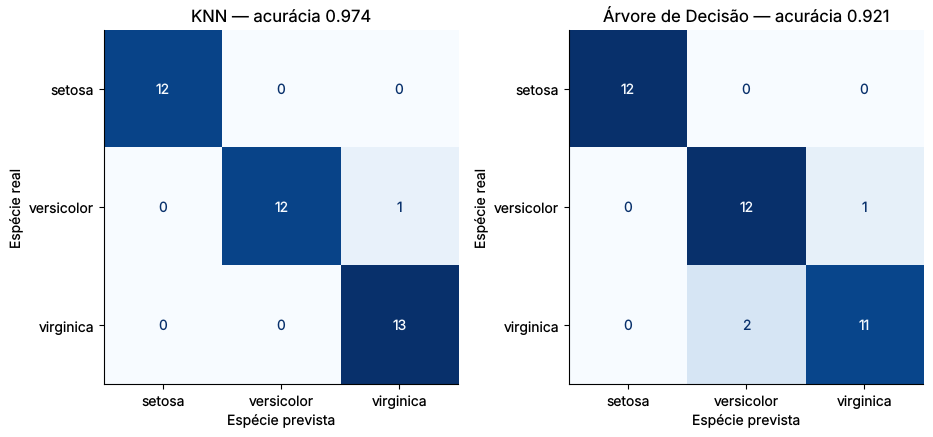

In [35]:
# Etapa 8: Árvore de Decisão com o mesmo treino/teste
from sklearn.tree import DecisionTreeClassifier

busca_arvore = GridSearchCV(DecisionTreeClassifier(random_state=123),
                            {'max_depth': [1, 2, 3, 4, 5, 6, None]},
                            cv=cv_aval, scoring='accuracy')
busca_arvore.fit(Xi_treino, yi_treino)
display(pd.DataFrame(busca_arvore.cv_results_)
        [['param_max_depth', 'mean_test_score', 'std_test_score', 'rank_test_score']].round(4))
print('Profundidade escolhida pela validação:', busca_arvore.best_params_)

arvore_final = busca_arvore.best_estimator_
yi_previsto_arvore = arvore_final.predict(Xi_teste)
print(f'Árvore escolhida — acurácia de teste: {accuracy_score(yi_teste, yi_previsto_arvore):.3f} '
      f'({np.trace(confusion_matrix(yi_teste, yi_previsto_arvore))} de {len(yi_teste)})')

# Referência: a árvore sem limite de profundidade (NÃO foi a escolhida pela validação)
arvore_livre = DecisionTreeClassifier(random_state=123).fit(Xi_treino, yi_treino)
print(f'Árvore sem limite (profundidade {arvore_livre.get_depth()}) — acurácia de teste: '
      f'{arvore_livre.score(Xi_teste, yi_teste):.3f}')

print('\nImportância dos atributos na árvore escolhida:')
display(pd.Series(arvore_final.feature_importances_, index=X_iris.columns, name='importância').round(3))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.6))
for eixo, (nome, prev) in zip(eixos, [('KNN', yi_previsto), ('Árvore de Decisão', yi_previsto_arvore)]):
    ConfusionMatrixDisplay.from_predictions(yi_teste, prev, display_labels=especies,
                                            cmap='Blues', colorbar=False, ax=eixo)
    eixo.set_title(f'{nome} — acurácia {accuracy_score(yi_teste, prev):.3f}')
    eixo.set_xlabel('Espécie prevista'); eixo.set_ylabel('Espécie real')
    eixo.grid(False)
salvar(fig, 'avaliativa_knn_vs_arvore')
plt.show()

#### Etapa 9 — Evidências para a conclusão: normalização e generalização

In [36]:
# Normalização: a mesma configuração escolhida, com e sem StandardScaler (validação no treino)
parametros_knn = {nome.replace('knn__', ''): valor for nome, valor in busca_final.best_params_.items()}
linhas = []
for k in valores_k:
    for rotulo, modelo in [('com padronização', clone(modelo_knn)),
                           ('sem padronização', Pipeline([('knn', KNeighborsClassifier())]))]:
        modelo.set_params(knn__n_neighbors=k, knn__weights=parametros_knn['weights'],
                          knn__p=parametros_knn['p'])
        linhas.append({'K': k, 'versão': rotulo,
                       'acurácia CV': cross_val_score(modelo, Xi_treino, yi_treino, cv=cv_aval).mean()})
normalizacao = pd.DataFrame(linhas).pivot(index='K', columns='versão', values='acurácia CV')
normalizacao['diferença (pontos)'] = 100 * (normalizacao['com padronização'] - normalizacao['sem padronização'])
print(f"Peso '{parametros_knn['weights']}', p={parametros_knn['p']}:")
display(normalizacao.round(3))
normalizacao.to_csv(PASTA_RESULTADOS / 'avaliativa_normalizacao.csv')

Peso 'distance', p=2:


versão,com padronização,sem padronização,diferença (pontos)
K,,,
1,0.920,0.946,-2.648
3,0.946,0.946,0.000
5,0.947,0.955,-0.870
7,0.947,0.955,-0.870
9,0.947,0.947,0.000
11,0.947,0.947,0.000
15,0.956,0.938,1.739


        KNN  Árvore  KNN - Árvore
mean  0.943   0.935         0.008
std   0.035   0.038         0.033
min   0.895   0.868        -0.053
max   1.000   1.000         0.079

KNN melhor em 12 sorteios, árvore melhor em 6, empate em 12.
K escolhido pela validação em cada sorteio (quantas vezes): {1: 1, 3: 3, 5: 11, 7: 3, 9: 2, 11: 4, 15: 6}


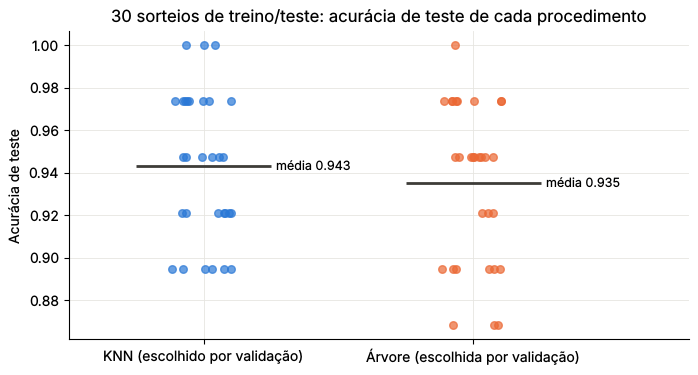

In [37]:
# Generalização: o procedimento INTEIRO (escolha por validação + teste único)
# repetido em 30 sorteios estratificados de treino/teste
linhas = []
for semente in range(30):
    a_tr, a_te, b_tr, b_te = train_test_split(X_iris, y_iris, test_size=0.25,
                                              random_state=semente, stratify=y_iris)
    knn_s = GridSearchCV(modelo_knn, grade_parametros, cv=cv_aval, n_jobs=-1).fit(a_tr, b_tr)
    arv_s = GridSearchCV(DecisionTreeClassifier(random_state=123),
                         {'max_depth': [1, 2, 3, 4, 5, 6, None]}, cv=cv_aval).fit(a_tr, b_tr)
    linhas.append({'random_state': semente, 'K escolhido': knn_s.best_params_['knn__n_neighbors'],
                   'KNN': knn_s.score(a_te, b_te), 'Árvore': arv_s.score(a_te, b_te)})
repeticoes = pd.DataFrame(linhas)
repeticoes['KNN - Árvore'] = repeticoes['KNN'] - repeticoes['Árvore']
repeticoes.to_csv(PASTA_RESULTADOS / 'avaliativa_repeticoes.csv', index=False)

print(repeticoes[['KNN', 'Árvore', 'KNN - Árvore']].describe().loc[['mean', 'std', 'min', 'max']].round(3))
print(f"\nKNN melhor em {(repeticoes['KNN - Árvore'] > 0).sum()} sorteios, "
      f"árvore melhor em {(repeticoes['KNN - Árvore'] < 0).sum()}, "
      f"empate em {(repeticoes['KNN - Árvore'] == 0).sum()}.")
print('K escolhido pela validação em cada sorteio (quantas vezes):',
      repeticoes['K escolhido'].value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(8, 4))
posicoes = np.arange(2)
for i, (nome, cor) in enumerate([('KNN', COR_TREINO), ('Árvore', COR_TESTE)]):
    valores = repeticoes[nome]
    deslocamento = np.random.default_rng(123).uniform(-0.12, 0.12, len(valores))
    ax.scatter(i + deslocamento, valores, color=cor, alpha=0.7, s=30)
    ax.hlines(valores.mean(), i - 0.25, i + 0.25, color='#3d3c38', linewidth=2)
    ax.annotate(f'média {valores.mean():.3f}', (i + 0.27, valores.mean()), va='center', fontsize=9)
ax.set_xticks(posicoes, ['KNN (escolhido por validação)', 'Árvore (escolhida por validação)'])
ax.set_xlim(-0.5, 1.8)
ax.set_ylabel('Acurácia de teste')
ax.set_title('30 sorteios de treino/teste: acurácia de teste de cada procedimento')
salvar(fig, 'avaliativa_repeticoes')
plt.show()

#### Resultados consolidados

In [38]:
# DataFrame com os resultados das diferentes configurações
import json

def linha_resultado(modelo, configuracao, papel, estimador=None, nota_cv=None, desvio_cv=None):
    linha = {'modelo': modelo, 'configuração': configuracao, 'papel': papel,
             'acurácia CV (média)': nota_cv, 'acurácia CV (desvio)': desvio_cv,
             'acurácia treino': np.nan, 'acurácia teste': np.nan}
    if estimador is not None:
        linha['acurácia treino'] = estimador.score(Xi_treino, yi_treino)
        linha['acurácia teste'] = estimador.score(Xi_teste, yi_teste)
    return linha

nome_peso = {'uniform': 'uniforme', 'distance': 'distância'}
nome_metrica = {1: 'Manhattan', 2: 'euclidiana'}
descricao_knn = f"{nome_peso[parametros_knn['weights']]}, {nome_metrica[parametros_knn['p']]}"

knn_padrao = clone(modelo_knn).set_params(knn__n_neighbors=5).fit(Xi_treino, yi_treino)
cv_padrao = tabela_k.set_index('K').loc[5]
cv_arvore = pd.DataFrame(busca_arvore.cv_results_).loc[busca_arvore.best_index_]
cv_livre = cross_val_score(DecisionTreeClassifier(random_state=123), Xi_treino, yi_treino, cv=cv_aval)

linhas = [
    linha_resultado('KNN', 'K=5, uniforme, euclidiana (exemplo da seção 7.1)', 'referência',
                    knn_padrao, cv_padrao['acurácia CV (média)'], cv_padrao['acurácia CV (desvio)']),
    linha_resultado('KNN', f"K={parametros_knn['n_neighbors']}, {descricao_knn}",
                    'ESCOLHIDO pela validação', modelo_final,
                    busca_final.best_score_, melhor['std_test_score']),
]
for variante in nomes_variante.values():
    sub = resultados_grade[resultados_grade['variante'] == variante]
    topo_variante = sub.loc[sub['mean_test_score'].idxmax()]
    linhas.append(linha_resultado('KNN', f"{variante}, melhor K={topo_variante['n_neighbors']}",
                                  'variante (só validação)', None,
                                  topo_variante['mean_test_score'], topo_variante['std_test_score']))
linhas.append(linha_resultado('KNN', f"K={normalizacao['sem padronização'].idxmax()}, {descricao_knn}, sem padronização",
                              'variante (só validação)', None,
                              normalizacao['sem padronização'].max(), None))
linhas += [
    linha_resultado('Árvore de Decisão', f"max_depth={busca_arvore.best_params_['max_depth']}",
                    'ESCOLHIDA pela validação', arvore_final,
                    busca_arvore.best_score_, cv_arvore['std_test_score']),
    linha_resultado('Árvore de Decisão', f'sem limite de profundidade (profundidade {arvore_livre.get_depth()})',
                    'referência', arvore_livre, cv_livre.mean(), cv_livre.std()),
]
resultados_finais = pd.DataFrame(linhas)
display(resultados_finais.round(3))
resultados_finais.to_csv(PASTA_RESULTADOS / 'avaliativa_resultados.csv', index=False)

resumo = {
    'n_treino': int(len(Xi_treino)), 'n_teste': int(len(Xi_teste)),
    'knn_parametros': {k: (int(v) if isinstance(v, (int, np.integer)) else v) for k, v in parametros_knn.items()},
    'knn_cv_media': float(busca_final.best_score_), 'knn_cv_desvio': float(melhor['std_test_score']),
    'knn_combinacoes_a_0001_do_melhor': int(proximas), 'knn_total_combinacoes': int(len(resultados_grade)),
    'knn_treino': float(modelo_final.score(Xi_treino, yi_treino)),
    'knn_teste_acuracia': float(acuracia_teste), 'knn_teste_acertos': int(np.trace(matriz_final)),
    'knn_teste_precisao_macro': float(precisao), 'knn_teste_recall_macro': float(recall),
    'knn_teste_f1_macro': float(f1), 'knn_matriz_confusao': matriz_final.tolist(),
    'arvore_max_depth': busca_arvore.best_params_['max_depth'],
    'arvore_cv_media': float(busca_arvore.best_score_),
    'arvore_treino': float(arvore_final.score(Xi_treino, yi_treino)),
    'arvore_teste_acuracia': float(accuracy_score(yi_teste, yi_previsto_arvore)),
    'arvore_matriz_confusao': confusion_matrix(yi_teste, yi_previsto_arvore).tolist(),
    'arvore_livre_profundidade': int(arvore_livre.get_depth()),
    'arvore_livre_teste_acuracia': float(arvore_livre.score(Xi_teste, yi_teste)),
    'arvore_importancias': {c: float(v) for c, v in zip(X_iris.columns, arvore_final.feature_importances_)},
    'peso_dif_media_pontos': float(100 * dif_peso.mean()),
    'peso_dif_min_pontos': float(100 * dif_peso.min()), 'peso_dif_max_pontos': float(100 * dif_peso.max()),
    'metrica_dif_media_pontos': float(100 * dif_metrica.mean()),
    'metrica_dif_min_pontos': float(100 * dif_metrica.min()), 'metrica_dif_max_pontos': float(100 * dif_metrica.max()),
    'normalizacao_dif_min_pontos': float(normalizacao['diferença (pontos)'].min()),
    'normalizacao_dif_max_pontos': float(normalizacao['diferença (pontos)'].max()),
    'normalizacao_com_no_k_escolhido': float(normalizacao.loc[parametros_knn['n_neighbors'], 'com padronização']),
    'normalizacao_sem_no_k_escolhido': float(normalizacao.loc[parametros_knn['n_neighbors'], 'sem padronização']),
    'repeticoes_n': int(len(repeticoes)),
    'repeticoes_knn_media': float(repeticoes['KNN'].mean()), 'repeticoes_knn_desvio': float(repeticoes['KNN'].std()),
    'repeticoes_arvore_media': float(repeticoes['Árvore'].mean()), 'repeticoes_arvore_desvio': float(repeticoes['Árvore'].std()),
    'repeticoes_knn_melhor': int((repeticoes['KNN - Árvore'] > 0).sum()),
    'repeticoes_arvore_melhor': int((repeticoes['KNN - Árvore'] < 0).sum()),
    'repeticoes_empates': int((repeticoes['KNN - Árvore'] == 0).sum()),
    'repeticoes_k_escolhido': {int(k): int(v) for k, v in repeticoes['K escolhido'].value_counts().sort_index().items()},
}
(PASTA_RESULTADOS / 'avaliativa_resumo.json').write_text(json.dumps(resumo, ensure_ascii=False, indent=2),
                                                         encoding='utf-8')
print('Resultados salvos em', PASTA_RESULTADOS.resolve())

,modelo,configuração,papel,acurácia CV (média),acurácia CV (desvio),acurácia treino,acurácia teste
0,KNN,"K=5, uniforme, euclidiana (exemplo da seção 7.1)",referência,0.938,0.045,0.955,0.947
1,KNN,"K=15, distância, euclidiana",ESCOLHIDO pela validação,0.956,0.028,1.000,0.974
2,KNN,"uniforme + euclidiana, melhor K=7",variante (só validação),0.947,0.033,NaN,NaN
3,KNN,"distância + euclidiana, melhor K=15",variante (só validação),0.956,0.028,NaN,NaN
4,KNN,"uniforme + Manhattan, melhor K=7",variante (só validação),0.955,0.040,NaN,NaN
5,KNN,"distância + Manhattan, melhor K=7",variante (só validação),0.955,0.040,NaN,NaN
6,KNN,"K=5, distância, euclidiana, sem padronização",variante (só validação),0.955,NaN,NaN,NaN
7,Árvore de Decisão,max_depth=3,ESCOLHIDA pela validação,0.946,0.033,0.964,0.921
8,Árvore de Decisão,sem limite de profundidade (profundidade 6),referência,0.937,0.036,1.000,0.974


Resultados salvos em /home/user/notebook_mindados/aulas/aula07_knn/resultados


**Interpretação e conclusão — Atividade 11**

**Desempenho.** A validação cruzada escolheu **K=15, pesos por distância e distância euclidiana**, com acurácia média de validação de **0,956**. Avaliado **uma única vez** no teste, o modelo acertou **37 das 38 flores (acurácia 0,974)**, com precisão, recall e F1 macro de **0,976 / 0,974 / 0,974**. A matriz de confusão mostra que o único erro foi **uma versicolor classificada como virginica**; a setosa foi perfeita. O ponto difícil da base é sempre a fronteira versicolor × virginica.

**Sensibilidade a K.** Na tabela da Etapa 4, K=1 tem acurácia de treino **1,000** — memorização, porque cada flor é a vizinha de si mesma — e a **pior validação (0,920)**. De K=3 a K=11 a validação fica entre **0,938 e 0,947**, e cai para **0,929** em K=15 (com pesos uniformes). A curva é **plana**: as diferenças entre K vizinhos são menores do que o desvio entre os folds (**0,03 a 0,05**). Isso se confirma na Etapa 5: **5 das 28 combinações** ficam a menos de 0,001 da melhor, e o K escolhido só vence na quarta casa decimal. Nos 30 sorteios da Etapa 9, a validação escolheu K=5 em 11 deles, K=15 em 6 e os demais em outros valores: **não existe um "K certo" para a Iris**, existe uma faixa de valores razoáveis.

**Pesos e métrica.** Em média, `distance` ficou **0,4 ponto acima** de `uniform`: ele **nunca piorou** a validação, empatou em 9 dos 14 casos e o maior ganho foi de 2,6 pontos, em **K=15** — com K grande, vizinhos mais distantes passariam a votar com o mesmo peso dos próximos, e o peso por distância corrige isso. Já entre euclidiana e Manhattan a diferença média foi de **−0,1 ponto**, praticamente nula, variando de −1,8 a +1,0 ponto conforme K, **sem um vencedor fixo**. Para dimensionar: na média dos 5 folds, cada flor vale cerca de 0,9 ponto, então essas diferenças são de no máximo três flores. Um detalhe importante: com `weights='distance'` a **acurácia de treino é sempre 1,000**, porque cada flor de treino está a distância zero de si mesma e recebe peso infinito. Por isso, nesse caso, a acurácia de treino não diz nada sobre memorização.

**Normalização.** Na Iris, a padronização **não foi decisiva**: as quatro medidas estão em centímetros e em escalas parecidas. No K escolhido ela ajudou (**0,956 com × 0,938 sem**), mas em K=1, 5 e 7 a versão **sem** padronização foi até melhor (em até 2,6 pontos) e em K=3, 9 e 11 houve empate: a diferença não tem sinal fixo, e a melhor versão sem padronização (0,955) fica praticamente igual à melhor com padronização. Isso contrasta com o exemplo sintético da seção 5, em que um atributo ×1000 derrubava a acurácia de 0,989 para 0,659. A lição é que **padronizar dentro do pipeline é a escolha segura**: custa pouco quando as escalas já são parecidas e evita um desastre quando não são.

**Comparação com a Árvore de Decisão.** Com o mesmo particionamento e o mesmo processo de escolha, a árvore escolhida (**max_depth=3**, empatada com 4 na validação) acertou **35 de 38 flores (0,921)**, duas a menos que o KNN, errando também na fronteira versicolor × virginica. Ela usa quase só o **comprimento da pétala** (importância 0,972). Mas a vantagem do KNN **não é robusta**: a árvore sem limite de profundidade, que a validação **não** escolheu, teria acertado 37 de 38 no teste — o mesmo que o KNN. E repetindo o procedimento inteiro em **30 sorteios**, o KNN teve média **0,943** e a árvore **0,935**: KNN melhor em 12, árvore em 6 e **empate em 12**. Há uma leve vantagem do KNN nesta base, menor que a variação de um sorteio para outro (desvio de cerca de 0,035).

**Limitações.** (1) **O teste tem só 38 flores**: cada flor vale 2,6 pontos percentuais, e uma diferença de uma ou duas flores entre modelos não é conclusiva. (2) A Iris é uma base **pequena, limpa, balanceada e com classes quase separáveis** — o caso mais favorável ao KNN, que costuma sofrer com muitos atributos, atributos irrelevantes e ruído. (3) O KNN **guarda toda a base de treino** e calcula distâncias a cada previsão: com milhões de registros, prever fica caro em tempo e memória. (4) O KNN não oferece regras legíveis como a árvore; a explicação de uma previsão é "estas flores parecidas".

**Generalização.** A distância pequena entre a validação (0,956) e o teste (0,974), e a média de **0,943 em 30 sorteios**, indicam que o modelo **generaliza bem para flores da mesma população**. O número mais honesto para relatar não é o 0,974 de um sorteio favorável, e sim algo **em torno de 0,94 a 0,96**, com variação de ±3 a 4 pontos dependendo de quais flores caem no teste. Generalizar para outras espécies, outras regiões ou outro instrumento de medição exigiria novos dados.

## 11. Revisão

**KNN:** algoritmo supervisionado, baseado em proximidade, capaz de classificação e regressão.

**K:** número de vizinhos. A escolha influencia flexibilidade, sensibilidade a ruído e generalização.

**Distância:** medida de semelhança entre registros. Euclidiana e Manhattan podem produzir diferentes vizinhanças.

**Normalização:** essencial para evitar que escalas numéricas muito diferentes dominem a distância. Use `Pipeline` para não contaminar o teste.

**Avaliação:** acurácia isolada pode esconder erros importantes; consulte matriz de confusão e métricas por classe.

**Validação cruzada:** escolha hiperparâmetros dentro do conjunto de treino, preservando o teste para uma avaliação final.

**Limitações do KNN:** custo de previsão e memória em bases grandes; sensibilidade à distância, ruído, atributos irrelevantes e alta dimensionalidade.

**Bibliografia e documentação:**

- CASTRO, Leandro Nunes de; FERRARI, Daniel Gomes. *Introdução à mineração de dados: conceitos básicos, algoritmos e aplicações*. São Paulo: Saraiva, 2016. Capítulo 5, seção 5.3.1.
- SOARES ARAUJO, Janniele Aparecida. *Mineração de Dados: classificação — Aula 18*. Material didático fornecido.
- SCIKIT-LEARN. *Nearest Neighbors* — documentação; `KNeighborsClassifier`; `Pipeline`.